In [1]:
import os
import gc
import glob
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import time
import io
import re
import tarfile
import warnings

In [ ]:
# # ===== 設定 =====
# ROOT = r"\\mis3c076\FTP_Root\WB_RPM_Log\process_data"
# TOP_ONLY = False          # True = 只檢查第一層子資料夾；False = 檢查所有層
# IGNORE_FILES = {"thumbs.db", "desktop.ini", ".ds_store"}   # 這些系統檔不算「有檔案」
# # ================


# def scan_empty_folders(root, top_only=False, ignore_files=IGNORE_FILES):
#     errors = []
#     no_files_in_subtree = {}
#     rows = []

#     def on_error(err):
#         errors.append({"path": getattr(err, "filename", ""), "error": str(err)})

#     # topdown=False：先處理子資料夾，再處理父資料夾
#     for dirpath, dirnames, filenames in os.walk(root, topdown=False, onerror=on_error):
#         real_files = [f for f in filenames if f.lower() not in ignore_files]
#         child_paths = [os.path.join(dirpath, d) for d in dirnames]

#         totally_empty = (len(real_files) == 0) and (len(dirnames) == 0)
#         subtree_no_files = (len(real_files) == 0) and all(
#             no_files_in_subtree.get(c, False) for c in child_paths
#         )
#         no_files_in_subtree[dirpath] = subtree_no_files

#         if os.path.normpath(dirpath) != os.path.normpath(root):
#             rows.append({
#                 "path": dirpath,
#                 "完全空": totally_empty,
#                 "子樹沒有檔案": subtree_no_files,
#             })

#     df = pd.DataFrame(rows, columns=["path", "完全空", "子樹沒有檔案"])

#     if top_only and not df.empty:
#         top_level = {
#             os.path.join(root, e.name)
#             for e in os.scandir(root)
#             if e.is_dir(follow_symlinks=False)
#         }
#         df = df[df["path"].isin(top_level)]

#     return df.sort_values("path").reset_index(drop=True), pd.DataFrame(errors)


# if not os.path.isdir(ROOT):
#     print(f"找不到資料夾或沒有權限：{ROOT}")
# else:
#     t0 = time.time()
#     df_folders, df_errors = scan_empty_folders(ROOT, top_only=TOP_ONLY)

#     print(f"檢查範圍：{'第一層子資料夾' if TOP_ONLY else '所有子資料夾（含各層）'}")
#     print(f"資料夾總數：{len(df_folders)}")
#     print(f"完全空的資料夾：{df_folders['完全空'].sum()}")
#     print(f"整棵子樹沒有任何檔案的資料夾：{df_folders['子樹沒有檔案'].sum()}（包含上一項）")
#     print(f"無法讀取的資料夾：{len(df_errors)}")
#     print(f"耗時：{time.time() - t0:.1f} 秒")

#     df_empty = df_folders[df_folders["子樹沒有檔案"]]
#     # display(df_empty)

檢查範圍：所有子資料夾（含各層）
資料夾總數：782
完全空的資料夾：687
整棵子樹沒有任何檔案的資料夾：687（包含上一項）
無法讀取的資料夾：0
耗時：3.0 秒


In [ ]:
# # 只取第一層（機台）資料夾，並排除「整棵子樹沒有任何檔案」的
# is_top_level = df_folders["path"].apply(
#     lambda p: os.path.normpath(os.path.dirname(p)) == os.path.normpath(ROOT)
# )
# df_nonempty = df_folders[is_top_level & ~df_folders["子樹沒有檔案"]]

# nonempty_eqp = sorted(df_nonempty["path"].apply(os.path.basename).tolist())

# # print(f"有資料的機台數：{len(nonempty_eqp)}")
# print(nonempty_eqp)
# # print(','.join(nonempty_eqp))

['WBR0001', 'WBR0004', 'WBR0005', 'WBR0024', 'WBR0026', 'WBR0033', 'WBR0034', 'WBR0038', 'WBR1001', 'WBR1004', 'WBR1006', 'WBR1008', 'WBR1014', 'WBR1018', 'WBR1020', 'WBR1021', 'WBR1023', 'WBR1026', 'WBR1034', 'WBR1037', 'WBR1039', 'WBR1040', 'WBR1041', 'WBR1043', 'WBR1045', 'WBR1050', 'WBR2022', 'WBR2025', 'WBR2053', 'WBR2057', 'WBR2065', 'WBR2076', 'WBR2077', 'WBR2115', 'WBR2130', 'WBR2132', 'WBR2150', 'WBR2170', 'WBR2173', 'WBR2174', 'WBR2180', 'WBR2183', 'WBR2192', 'WBR2194', 'WBR2195', 'WBR2196', 'WBR2212', 'WBR2214', 'WBR2215', 'WBR2217', 'WBR2221', 'WBR2222', 'WBR2226', 'WBR2228', 'WBR2233', 'WBR2235', 'WBR2236', 'WBR2239', 'WBR2274', 'WBR4018', 'WBR4019', 'WBR4020', 'WBR6006', 'WBR6051', 'WBR6054', 'WBR6072', 'WBR6079', 'WBR6092', 'WBR6096', 'WBR6128', 'WBR6136', 'WBR6137', 'WBR6139', 'WBR6146', 'WBR6147', 'WBR6149', 'WBR6150', 'WBR6176', 'WBR6191', 'WBR6201', 'WBR6204', 'WBR6207', 'WBR6209', 'WBR6210', 'WBR6211', 'WBR6213', 'WBR6217', 'WBR6219', 'WBR6220', 'WBR6223', 'WBR6239'

In [ ]:
# print(','.join(nonempty_eqp))

WBR0001,WBR0004,WBR0005,WBR0024,WBR0026,WBR0033,WBR0034,WBR0038,WBR1001,WBR1004,WBR1006,WBR1008,WBR1014,WBR1018,WBR1020,WBR1021,WBR1023,WBR1026,WBR1034,WBR1037,WBR1039,WBR1040,WBR1041,WBR1043,WBR1045,WBR1050,WBR2022,WBR2025,WBR2053,WBR2057,WBR2065,WBR2076,WBR2077,WBR2115,WBR2130,WBR2132,WBR2150,WBR2170,WBR2173,WBR2174,WBR2180,WBR2183,WBR2192,WBR2194,WBR2195,WBR2196,WBR2212,WBR2214,WBR2215,WBR2217,WBR2221,WBR2222,WBR2226,WBR2228,WBR2233,WBR2235,WBR2236,WBR2239,WBR2274,WBR4018,WBR4019,WBR4020,WBR6006,WBR6051,WBR6054,WBR6072,WBR6079,WBR6092,WBR6096,WBR6128,WBR6136,WBR6137,WBR6139,WBR6146,WBR6147,WBR6149,WBR6150,WBR6176,WBR6191,WBR6201,WBR6204,WBR6207,WBR6209,WBR6210,WBR6211,WBR6213,WBR6217,WBR6219,WBR6220,WBR6223,WBR6239,WBR6240,WBR6265,WBR6267,WBR6269


### 讀取 PDT-UNEXPECTED-NSOP 資料

In [2]:
import pandas as pd

path = r"C:\Users\A134549\Downloads\event_nsop_record_1102_1108.csv"

# 依序嘗試常見編碼
for enc in ["utf-8-sig", "cp950", "latin-1"]:
    try:
        df_nsop = pd.read_csv(path, encoding=enc, low_memory=False)
        break
    except UnicodeDecodeError:
        continue

df_nsop.columns = df_nsop.columns.str.strip()   # 去掉欄位名稱前後的空白

machine_list = sorted(
    df_nsop["MACHINECODE"].dropna().astype(str).str.strip().unique().tolist()
)

print(f"資料筆數：{len(df_nsop):,}")
print(f"MACHINECODE 唯一值數量：{len(machine_list)}")
print(", ".join(machine_list))
before = len(df_nsop)
machine_list=machine_list[:20]
keep = {m.strip().upper() for m in machine_list}


df_nsop = df_nsop[
    df_nsop["MACHINECODE"].astype(str).str.strip().str.upper().isin(keep)
].reset_index(drop=True)

print(f"篩選前：{before} 筆，篩選後：{len(df_nsop)} 筆")
print(f"篩選後的機台數：{df_nsop['MACHINECODE'].nunique()}")

資料筆數：641
MACHINECODE 唯一值數量：87
WBR0001, WBR0004, WBR0005, WBR0033, WBR0034, WBR0038, WBR1001, WBR1004, WBR1006, WBR1008, WBR1014, WBR1018, WBR1020, WBR1021, WBR1023, WBR1026, WBR1034, WBR1037, WBR1039, WBR1040, WBR1041, WBR1043, WBR1050, WBR2022, WBR2025, WBR2053, WBR2057, WBR2065, WBR2076, WBR2077, WBR2115, WBR2130, WBR2132, WBR2150, WBR2170, WBR2173, WBR2174, WBR2180, WBR2183, WBR2192, WBR2194, WBR2195, WBR2212, WBR2214, WBR2215, WBR2217, WBR2221, WBR2222, WBR2226, WBR2228, WBR2233, WBR2235, WBR2236, WBR2239, WBR2274, WBR4018, WBR4019, WBR4020, WBR6006, WBR6072, WBR6079, WBR6092, WBR6096, WBR6128, WBR6136, WBR6137, WBR6139, WBR6146, WBR6147, WBR6149, WBR6150, WBR6176, WBR6191, WBR6201, WBR6204, WBR6207, WBR6209, WBR6210, WBR6211, WBR6213, WBR6217, WBR6219, WBR6220, WBR6223, WBR6239, WBR6240, WBR6267
篩選前：641 筆，篩選後：186 筆
篩選後的機台數：20


In [3]:
df_nsop.head()

,SHIFTDATE,CLASS,DNSHIFT,PROCESS,LOCATION,FLOOR,MACHINECODE,LOTNO,PROGRAMNAME,EVENTCODE,EVENTMESSAGE,EVENTTIME,MAJORCODEID,MUBA,MFGDEPT,DEVICE,INSERTDT,DATA_YEAR
0,2026-11-06 00:00:00,5,N,W/B,3A,5F,WBR1014,2610T2635.06,SMIM32DGG308-01-EM-01,142,PDT-UNEXPECTED-NSOP,2026/11/06 19:58:36,0,1,AP 33,NC14N17M51PTP34352-STK-N47-HVM(CTRL,2026/11/06 20:30:48,2026
1,2026-11-06 00:00:00,5,N,W/B,3A,5F,WBR1034,M26BZ0592.00,SMIM97AGG328-00-MP-00,142,PDT-UNEXPECTED-NSOP,2026/11/06 19:55:44,0,1,AP 33,UM2377XLPTIP30996-STK-SS-BA-HVM-CIP,2026/11/06 20:30:48,2026
2,2026-11-06 00:00:00,5,N,W/B,3A,5F,WBR1034,M26BZ0592.00,SMIM97AGG328-00-MP-00,142,PDT-UNEXPECTED-NSOP,2026/11/06 20:59:41,0,1,AP 33,UM2377XLPTIP30996-STK-SS-BA-HVM-CIP,2026/11/06 21:30:48,2026
3,2026-11-06 00:00:00,5,N,W/B,2B,4F,WBR0033,M26BZ0388.00,SMIM63HDG404-00-AM-02,142,PDT-UNEXPECTED-NSOP,2026/11/06 21:36:51,0,1,AP 23,Y62P6JR96PTP31364-MSH-HVM2-CIP(M2,2026/11/06 22:30:47,2026
4,2026-11-06 00:00:00,5,N,W/B,2B,4F,WBR1006,M26BY9546.00,SMIM54EGG303-01-KF-01,142,PDT-UNEXPECTED-NSOP,2026/11/06 22:20:12,0,1,AP 23,NC17P17D6PTP36045-K5A-SMBP-HVM(M1,2026/11/06 22:30:49,2026


In [5]:
# warnings.filterwarnings("ignore", message="The behavior of DataFrame concatenation with empty or all-NA entries")
# # ===== 設定 =====
# ROOT = r"\\mis3c076\FTP_Root\WB_RPM_Log\process_data"
# OUT_DIR = r"C:\Users\A134549\rpm_parquet_11021108"     # 存到本機硬碟，不要存回網路磁碟
# DATE_START = "2026-11-02"                      # 只保留這段期間的資料（含）
# DATE_END = "2026-11-09"                        # 不含這一天；設成 None 則不篩選日期
# KEEP_COLS = None                               # None = 全部欄位；或填欄位名稱 list 只留需要的
# MAX_FILES_PER_EQP = None                       # 測試時先設成 1
# ONLY_DEEPEST = True                            # True = 每個壓縮檔只取最深一層的 csv
# ENCODINGS = ["utf-8-sig", "cp950", "latin-1"]  # 依序嘗試的編碼
# # ================

# os.makedirs(OUT_DIR, exist_ok=True)

# # 檔名格式：..._2026-11-01T02-25-22_2026-11-01T03-25-22.csv（開始時間_結束時間）
# FNAME_TIME = re.compile(
#     r"(\d{4}-\d{2}-\d{2})T(\d{2})-(\d{2})-(\d{2})_(\d{4}-\d{2}-\d{2})T(\d{2})-(\d{2})-(\d{2})"
# )
# skipped_csv = 0


# def csv_in_range(filename):
#     """依檔名的開始、結束時間判斷要不要讀。檔名格式不符時一律讀取。"""
#     m = FNAME_TIME.search(filename)
#     if not m:
#         return True
#     start = pd.Timestamp(f"{m.group(1)} {m.group(2)}:{m.group(3)}:{m.group(4)}")
#     end = pd.Timestamp(f"{m.group(5)} {m.group(6)}:{m.group(7)}:{m.group(8)}")
#     if DATE_END and start >= pd.Timestamp(DATE_END):    # 開始和結束都在範圍之後
#         return False
#     if DATE_START and end < pd.Timestamp(DATE_START):   # 整段都在範圍之前
#         return False
#     return True


# def read_csv_bytes(raw):
#     """用多種編碼嘗試讀取 csv 內容。"""
#     last_err = None
#     for enc in ENCODINGS:
#         try:
#             return pd.read_csv(io.BytesIO(raw), encoding=enc, low_memory=False)
#         except UnicodeDecodeError as e:
#             last_err = e
#     raise last_err


# def read_tarxz(path):
#     """讀一個 .tar.xz，回傳 (合併後的 DataFrame 或 None, 錯誤清單)。"""
#     global skipped_csv
#     found, errs = [], []
#     # 'r|xz' 是串流模式：只解壓一次，網路磁碟上比隨機讀取快很多
#     with tarfile.open(path, mode="r|xz") as tar:
#         for m in tar:
#             name = m.name
#             base = os.path.basename(name)
#             if not m.isfile() or not base.lower().endswith(".csv") or base.startswith("._"):
#                 continue
#             if not csv_in_range(base):          # 依檔名時間跳過不需要的 csv
#                 skipped_csv += 1
#                 continue
#             try:
#                 raw = tar.extractfile(m).read()
#                 if not raw.strip():
#                     continue
#                 df = read_csv_bytes(raw)
#                 if df.empty:
#                     continue
#                 found.append((name.strip("/").count("/"), name, df))
#             except Exception as e:
#                 errs.append({"archive": path, "member": name, "error": str(e)})
#     if not found:
#         return None, errs
#     if ONLY_DEEPEST:
#         max_depth = max(d for d, _, _ in found)
#         found = [x for x in found if x[0] == max_depth]
#     parts = []
#     for _, name, df in found:
#         df["source_csv"] = name
#         parts.append(df)
#     return pd.concat(parts, ignore_index=True), errs

# def shrink(df):
#     for c in df.select_dtypes(include=["float64", "int64", "int32", "int16", "int8"]).columns:
#         df[c] = df[c].astype("float32")
#     return df


# # 只處理 machine_list 裡、在 ROOT 底下有資料夾的機台
# target_eqp = sorted(m.strip() for m in machine_list if os.path.isdir(os.path.join(ROOT, m.strip())))
# print(f"machine_list：{len(machine_list)} 台，找得到資料夾：{len(target_eqp)} 台\n")

# error_log = []
# written, skipped, total_rows = 0, 0, 0
# t0 = time.time()

# for eqp in target_eqp:
#     tar_files = []
#     for dirpath, _, filenames in os.walk(os.path.join(ROOT, eqp)):
#         tar_files += [os.path.join(dirpath, f) for f in filenames if f.lower().endswith(".tar.xz")]
#     tar_files.sort()
#     if MAX_FILES_PER_EQP:
#         tar_files = tar_files[:MAX_FILES_PER_EQP]
#     print(f"{eqp}：{len(tar_files)} 個 .tar.xz")

#     for path in tar_files:
#         out_name = f"{eqp}__{os.path.basename(path).replace('.tar.xz', '')}.parquet"
#         out_path = os.path.join(OUT_DIR, out_name)
#         if os.path.exists(out_path):          # 已經處理過就跳過，中斷後可以接著跑
#             skipped += 1
#             continue
#         df = None
#         try:
#             df, errs = read_tarxz(path)
#             error_log.extend(errs)
#             if df is None:
#                 continue

#             if KEEP_COLS:
#                 df = df[[c for c in KEEP_COLS if c in df.columns] + ["source_csv"]].copy()

#             if DATE_START and "Timestamp" in df.columns:
#                 ts = pd.to_datetime(df["Timestamp"], errors="coerce")
#                 mask = ts >= pd.Timestamp(DATE_START)
#                 if DATE_END:
#                     mask &= ts < pd.Timestamp(DATE_END)
#                 df = df[mask].copy()
#                 if df.empty:
#                     continue

#             df["source_eqp"] = eqp
#             df["source_archive"] = os.path.basename(path)
#             df = shrink(df)
#             df.to_parquet(out_path, index=False)
#             written += 1
#             total_rows += len(df)
#         except Exception as e:
#             error_log.append({"archive": path, "member": "", "error": str(e)})
#         finally:
#             df = None
#             gc.collect()

# df_errors_tar = pd.DataFrame(error_log)
# print(f"\n新寫入 parquet 檔：{written}，已存在跳過：{skipped}")
# print(f"新寫入資料筆數：{total_rows:,}")
# print(f"依檔名時間跳過的 csv：{skipped_csv}")
# print(f"讀取失敗：{len(df_errors_tar)} 筆")
# print(f"耗時：{time.time() - t0:.1f} 秒")

WBR0034因為CSV裡面的Timestamp超出日期範圍所以沒有下載

### 讀取 W/B LOG (Parquet)

In [4]:
def read_dir(path, cols=None, max_files=None):
    parts = []
    files = sorted(glob.glob(os.path.join(path, "*.parquet")))[:max_files]
    for f in files:
        names = pq.read_schema(f).names
        d = pd.read_parquet(f, columns=[c for c in cols if c in names] if cols else None)
        for c in d.columns:
            if pd.api.types.is_numeric_dtype(d[c]) and not pd.api.types.is_bool_dtype(d[c]):
                d[c] = d[c].astype("float32")
        parts.append(d)
    return pd.concat(parts, ignore_index=True)

In [7]:
cols = ['Timestamp',	'EQP',	'Recipe',	'Device',	'Bond Program',	'Lot Id',	'Output Mag Id',	'Output Mag Slot',	'Leadframe Id',	'Index Id'	,'Device Id',	'Device Column','Device Row',	'Ref Sys',	'EP Set',	'EP 1 Score',	'EP 2 Score',	'Wire Id',	'Bond Seq Num'	,'Bond Type',	'RPM PRS ID',	'Die Height (mil)',	'Die Tilt (deg)','Die Placement X (mil)',
 'Die Placement Y (mil)','Die Rotation (degfor)',	'Bond Height Delta (mil)'	,'Deformation (Cont) (um)'	,'Deformation (TD) (um)','Ball Diam (mil)','Ball Place X (mil)','Ball Place Y (mil)','USG current (mA)'	,'Force','EFO Voltage Avg (V)'	,'Z at Contact (um)',	'Z at End of Bonding (um)'	,'Bond Height Detection (um)','Ball Height (TD) (um)','Ball Height (Cont) (um)'	,'Impedance Ratio 1','Impedance Ratio 2']
# df = pd.read_parquet(r"C:\Users\A134549\rpm_parquet_11021108", columns=cols)
df = read_dir(r"C:\Users\A134549\rpm_parquet_11021108", cols, max_files=3)
print(f"{len(df):,} 筆，約 {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
print(df.shape)
df.head()

934,409 筆，約 0.73 GB
(934409, 42)


,Timestamp,EQP,Recipe,Device,Bond Program,Lot Id,Output Mag Id,Output Mag Slot,Leadframe Id,Index Id,...,USG current (mA),Force,EFO Voltage Avg (V),Z at Contact (um),Z at End of Bonding (um),Bond Height Detection (um),Ball Height (TD) (um),Ball Height (Cont) (um),Impedance Ratio 1,Impedance Ratio 2
0,2026-11-02 05:00:00.450,WBR0001,SMIM97AGG328-00-MP-00,UM2377XLPTIP30996-STK-SS-BA-HVM-CIP,UM237_3A,M26AS7585.00,12687_2026-11-01_03-54-o009,10.0,BXBM67026409-0405,1.0,...,47.939999,13.16,0.0,109.110001,107.360001,NaN,NaN,NaN,1.19,1.08
1,2026-11-02 04:59:59.983,WBR0001,SMIM97AGG328-00-MP-00,UM2377XLPTIP30996-STK-SS-BA-HVM-CIP,UM237_3A,M26AS7585.00,12687_2026-11-01_03-54-o009,10.0,BXBM67026409-0405,1.0,...,47.919998,13.02,0.0,110.589996,108.629997,0.98,NaN,NaN,1.19,1.08
2,2026-11-02 04:59:59.833,WBR0001,SMIM97AGG328-00-MP-00,UM2377XLPTIP30996-STK-SS-BA-HVM-CIP,UM237_3A,M26AS7585.00,12687_2026-11-01_03-54-o009,10.0,BXBM67026409-0405,1.0,...,47.930000,13.05,0.0,109.620003,107.820000,NaN,NaN,NaN,1.19,1.08
3,2026-11-02 04:59:47.033,WBR0001,SMIM97AGG328-00-MP-00,UM2377XLPTIP30996-STK-SS-BA-HVM-CIP,UM237_3A,M26AS7585.00,12687_2026-11-01_03-54-o009,10.0,BXBM67026409-0405,1.0,...,47.930000,13.43,0.0,109.199997,107.580002,-0.38,NaN,NaN,1.19,1.09
4,2026-11-02 05:00:00.300,WBR0001,SMIM97AGG328-00-MP-00,UM2377XLPTIP30996-STK-SS-BA-HVM-CIP,UM237_3A,M26AS7585.00,12687_2026-11-01_03-54-o009,10.0,BXBM67026409-0405,1.0,...,47.939999,13.28,0.0,109.059998,107.330002,-0.25,NaN,NaN,1.19,1.08


In [8]:
del df
gc.collect()

1417

In [5]:
# ===== 設定 =====
NSOP_PATH = r"C:\Users\A134549\Downloads\event_nsop_record_1102_1108.csv"
PARQUET_DIR = r"C:\Users\A134549\rpm_parquet_11021108"        # 之前存好的 RPM parquet
LABEL_DIR = r"C:\Users\A134549\rpm_parquet_labeled_11021108"  # 加上標記後的輸出位置
NSOP_EQP_COL = "MACHINECODE"
NSOP_TIME_COL = "EVENTTIME"     # 先跑一次看欄位名稱，再填入 NSOP 發生時間的欄位，例如 "EVENTTIME"
RPM_TIME_COL = "Timestamp"
MATCH_TOL_MIN = 5        # NSOP 時間和最近一筆 RPM 紀錄最多差幾分鐘，仍視為對得上
# ================


In [7]:
# assert NSOP_TIME_COL, "請先在設定區填入 NSOP_TIME_COL，再執行這個 cell"

# ---------- NSOP 事件整理 ----------
ctx_cols = [c for c in ["LOTNO", "PROGRAMNAME", "DEVICE"] if c in df_nsop.columns]
ev = df_nsop[[NSOP_EQP_COL, NSOP_TIME_COL] + ctx_cols].copy()#從df_nsop取出這三個欄位"LOTNO", "PROGRAMNAME", "DEVICE"，複製成新表ev。
ev["eqp"] = ev[NSOP_EQP_COL].astype(str).str.strip().str.upper()#機台編號去掉前後空白、轉大寫
raw = ev[NSOP_TIME_COL].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()#時間欄位裡的Tab、連續空格都換成單一空格
ev["nsop_time"] = pd.to_datetime(raw, format="%Y/%m/%d %H:%M:%S", errors="coerce")#依2026/10/29 02:22:03的形式轉換時間，轉不了的話變成空值
miss = ev["nsop_time"].isna()
ev.loc[miss, "nsop_time"] = pd.to_datetime(raw[miss], format="mixed", errors="coerce")  # 其他格式備援
n_bad_time = int(ev["nsop_time"].isna().sum())#計算最後仍無法轉換的筆數
ev = (ev.dropna(subset=["nsop_time"]) #刪除時間空值
        .drop_duplicates(["eqp", "nsop_time"]) #刪掉同機台同一秒的重複事件
        .sort_values(["eqp", "nsop_time"]) #依機台與時間排序
        .reset_index(drop=True))
ev["nsop_time"] = ev["nsop_time"].astype("datetime64[ns]")#時間統一成奈秒精度。RPM那邊也是這個精度，兩邊一致這樣後面才可以配對
ev["event_id"] = np.arange(len(ev))#每個事件編號0,1,2....，方便追蹤

# ---------- RPM 檔案依機台分組 ----------
pq_files = sorted(glob.glob(os.path.join(PARQUET_DIR, "*.parquet")))
files_by_eqp = {}
for f in pq_files:#從parquet檔名取出機台編號並建立成一個字典，之後如果要讀取特定機台，只需要讀他自己的parquet檔案
    files_by_eqp.setdefault(os.path.basename(f).split("__")[0].strip().upper(), []).append(f)

MAP_COLS = [RPM_TIME_COL, "Lot Id", "Recipe"]

def load_rpm(eqp, cols):
    """讀一台機台的 RPM 資料（只讀指定欄位），依時間排序。"""
    parts = []
    for f in files_by_eqp.get(eqp, []):#只取出該機台的parquet檔案
        use = [c for c in cols if c in pq.read_schema(f).names]#pq.read_schema:只讀檔案的欄位清單，不讀資料，用來確認欄位存在，避免某個檔案缺欄位時報錯
        parts.append(pd.read_parquet(f, columns=use))
    if not parts:
        return None
    d = pd.concat(parts, ignore_index=True)#將這些parquet檔案合併成一個dataframe
    d["rpm_time"] = pd.to_datetime(d[RPM_TIME_COL], errors="coerce").astype("datetime64[ns]")
    return d.dropna(subset=["rpm_time"]).sort_values("rpm_time", kind="stable").reset_index(drop=True)


# ---------- 用「機台 + 時間」對應 ----------
maps, typical_gaps = [], []
for eqp, g in ev.groupby("eqp"):#先從ev資料(從csv資料來的)中用機台編號來分組，eqp是機台編號、g是每筆分組後的資料
    g = g.sort_values("nsop_time")#再依時間排序
    rpm = load_rpm(eqp, MAP_COLS)#讀取該機台資料(rpm資料)
    if rpm is None: #如果出現在csv檔案(錯誤事件資料)的機台，但卻在rpm資料裡沒有的機台#直接保留這些事件，並標記has_rpm=False
        maps.append(g.assign(has_rpm=False))
        continue

    # 事件時間最接近的那一筆 RPM 紀錄：當時在打哪個 Lot / 導線架 / IC / 線
    m = pd.merge_asof(g, rpm.drop(columns=[RPM_TIME_COL]),#先拿掉原本在rpm原始資料裡的"Timestamp"欄位，因為之後不會用到了。mapping時是使用rpm_time這個經過整理後的時間
                      left_on="nsop_time", right_on="rpm_time", direction="nearest",
                      tolerance=pd.Timedelta(minutes=MATCH_TOL_MIN))
    m["has_rpm"] = True

    # pd.merge_asof: 
    # •	對每個 NSOP 事件，在 RPM 裡找時間最接近的一筆（direction="nearest"，前後都算）。
	# •	超過 MATCH_TOL_MIN（10 分鐘）就不配，那幾個欄位留空。
	# •	配到後，把那一筆的 Lot、Recipe、Wire Id 等欄位接到事件旁邊。

    # 事件前最後一筆、事件後第一筆 RPM 紀錄：NSOP 會停機，事件後應該有一段明顯的空白
    t = rpm["rpm_time"].values
    et = m["nsop_time"].values.astype("datetime64[ns]")
    i = np.searchsorted(t, et, side="right")#用 np.searchsorted 找出事件時間在 RPM 時間軸上的位置
    m["prev_row_time"] = np.where(i > 0, t[np.maximum(i - 1, 0)], np.datetime64("NaT", "ns"))
    m["next_row_time"] = np.where(i < len(t), t[np.minimum(i, len(t) - 1)], np.datetime64("NaT", "ns"))
    if len(t) > 1:
        typical_gaps.append(np.median(np.diff(t)) / np.timedelta64(1, "s"))#這台機台正常情況下，兩筆紀錄間隔多久:把排序後的時間兩兩相減，取中位數，用來和事件前後的間隔比較

    maps.append(m)
    del rpm#處理完就刪掉這台機台的資料，釋放記憶體
    gc.collect()

df_map = pd.concat(maps, ignore_index=True)
df_map["diff_to_rpm_sec"] = (df_map["rpm_time"] - df_map["nsop_time"]).dt.total_seconds()#最接近的那筆RPM和NSOP發生事件差幾秒
df_map["sec_from_prev_row"] = (df_map["nsop_time"] - df_map["prev_row_time"]).dt.total_seconds()#事件前最後一筆紀錄，距離事件幾秒
df_map["sec_to_next_row"] = (df_map["next_row_time"] - df_map["nsop_time"]).dt.total_seconds()#事件後過幾秒才有下一筆紀錄


# ---------- 檢查對應得對不對：Lot / Program / Device 是否一致 ----------
def same(a, b):
    return (df_map[a].astype(str).str.strip().str.upper()
            == df_map[b].astype(str).str.strip().str.upper())

checks = [("LOTNO", "Lot Id", "Lot"), ("PROGRAMNAME", "Recipe", "Program / Recipe")]

print(f"NSOP 事件數：{len(ev):,}（時間無法解析而排除：{n_bad_time}）")
print(f"機台有 RPM 資料的事件：{int(df_map['has_rpm'].sum()):,}")
matched = df_map["rpm_time"].notna()
print(f"{MATCH_TOL_MIN} 分鐘內找得到 RPM 紀錄的事件：{int(matched.sum()):,}")

print("\n【對應品質 1】事件當下的 Lot / Program / Device 是否和 RPM 一致")
for a, b, label in checks:
    if a in df_map.columns and b in df_map.columns:
        both = matched & df_map[a].notna() & df_map[b].notna()
        eq = both & same(a, b)
        print(f"  {label}：兩邊都有值 {int(both.sum())} 筆，一致 {int(eq.sum())} 筆")
        df_map[f"{label}_match"] = np.where(both, eq, np.nan)

print("\n【對應品質 2】NSOP 停機：事件前後 RPM 紀錄的間隔（秒）")
if typical_gaps:
    print(f"  正常情況下相鄰兩筆紀錄間隔的中位數：約 {np.median(typical_gaps):.2f} 秒")
sub = df_map.loc[df_map["has_rpm"] == True, ["sec_from_prev_row", "sec_to_next_row"]]
print(sub.describe(percentiles=[.1, .25, .5, .75, .9]).round(1).to_string())

display(df_map.head())

NSOP 事件數：186（時間無法解析而排除：0）
機台有 RPM 資料的事件：179
5 分鐘內找得到 RPM 紀錄的事件：134

【對應品質 1】事件當下的 Lot / Program / Device 是否和 RPM 一致
  Lot：兩邊都有值 134 筆，一致 134 筆
  Program / Recipe：兩邊都有值 124 筆，一致 123 筆

【對應品質 2】NSOP 停機：事件前後 RPM 紀錄的間隔（秒）
  正常情況下相鄰兩筆紀錄間隔的中位數：約 0.14 秒
       sec_from_prev_row  sec_to_next_row
count              166.0            152.0
mean             25873.8           6314.4
std              85402.7          22522.2
min                  0.0              0.0
10%                  0.1              0.1
25%                  0.1              0.1
50%                  1.0            151.0
75%                894.3            973.8
90%              35860.0           8500.3
max             513927.0         177346.6


,MACHINECODE,EVENTTIME,LOTNO,PROGRAMNAME,DEVICE,eqp,nsop_time,event_id,Lot Id,Recipe,rpm_time,has_rpm,prev_row_time,next_row_time,diff_to_rpm_sec,sec_from_prev_row,sec_to_next_row,Lot_match,Program / Recipe_match
0,WBR0001,2026/11/03 14:00:05,M26BZ8552.00,SMIM97AGG328-00-MP-00,UM2377XLPTIP30996-MSTK-SS-BA-HVM-CIP,WBR0001,2026-11-03 14:00:05,0,M26BZ8552.00,SMIM97AGG328-00-MP-00,2026-11-03 14:00:04.933,True,2026-11-03 14:00:04.933,2026-11-03 14:00:05.083,-0.067,0.067,0.083,1.0,1.0
1,WBR0001,2026/11/03 14:21:31,M26BZ8552.00,SMIM97AGG328-00-MP-00,UM2377XLPTIP30996-MSTK-SS-BA-HVM-CIP,WBR0001,2026-11-03 14:21:31,1,M26BZ8552.00,SMIM97AGG328-00-MP-00,2026-11-03 14:21:30.900,True,2026-11-03 14:21:30.900,2026-11-03 14:21:31.150,-0.100,0.100,0.150,1.0,1.0
2,WBR0001,2026/11/04 23:37:43,M26BZ4687.00,SMIM97AGG328-00-MP-00,UM2377XLPTIP30996-STK-SS-BA-HVM-CIP,WBR0001,2026-11-04 23:37:43,2,M26BZ4687.00,SMIM97AGG328-00-MP-00,2026-11-04 23:37:40.016,True,2026-11-04 23:37:40.016,2026-11-04 23:38:09.166,-2.984,2.984,26.166,1.0,1.0
3,WBR0001,2026/11/05 10:49:26,M26BZ4492.00,SMIM97AGG328-00-MP-00,UM2377XLPTIP30996-STK-SS-BA-HVM-CIP,WBR0001,2026-11-05 10:49:26,3,M26BZ4492.00,SMIM97AGG328-00-MP-00,2026-11-05 10:49:24.800,True,2026-11-05 10:49:24.800,2026-11-05 10:58:00.700,-1.200,1.200,514.700,1.0,1.0
4,WBR0001,2026/11/06 22:41:41,M26BY8028.00,SMIM97AGG328-00-MP-00,UM2377XLPTIP30996-STK-SS-BA-HVM-CIP,WBR0001,2026-11-06 22:41:41,4,M26BY8028.00,SMIM97AGG328-00-MP-00,2026-11-06 22:42:29.483,True,2026-11-06 22:20:03.350,2026-11-06 22:42:29.483,48.483,1297.650,48.483,1.0,1.0


In [17]:
ALL_EVT_PATH = r"C:\Users\A134549\Downloads\event_all_record_1102_1108.csv"

for enc in ["utf-8-sig", "cp950", "latin-1"]:
    try:
        df_evt = pd.read_csv(ALL_EVT_PATH, encoding=enc, low_memory=False)
        break
    except UnicodeDecodeError:
        continue
df_evt.columns = df_evt.columns.str.strip()
df_evt["eqp"] = df_evt["MACHINECODE"].astype(str).str.strip().str.upper()
df_evt["evt_time"] = pd.to_datetime(
    df_evt["EVENTTIME"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip(),
    format="%Y/%m/%d %H:%M:%S", errors="coerce")
df_evt = df_evt[df_evt["eqp"].isin(files_by_eqp.keys())].dropna(subset=["evt_time"])

print(f"這 {df_evt['eqp'].nunique()} 台機台、這一週的事件總數：{len(df_evt):,}")
display(df_evt["EVENTMESSAGE"].value_counts().to_frame("次數"))

這 18 台機台、這一週的事件總數：2,219


,次數
EVENTMESSAGE,
ALIGN status - inadequate eye points found,284
PBI-WIRE-STOP-ERR,221
PDT-UNEXPECTED-SHTL,217
PDT-UNEXPECTED-NSOP,179
EH_CNG_BOND_COUNTERS_EXCEEDED,177
EH_MON_IDLE_CLAMP_OPEN_TIMEOUT,155
MON-UPS-BAD-BATTERY,154
PDT-UNEXPECTED-NSOL,109
PDT-WIREFEED-ERROR,84


recipe有不一樣的

In [9]:
# bad = df_map[df_map["Program / Recipe_match"] == 0]
# display(bad[["eqp", "nsop_time", "LOTNO", "Lot Id", "PROGRAMNAME", "Recipe",
#              "rpm_time", "diff_to_rpm_sec", "sec_from_prev_row", "sec_to_next_row"]])

In [10]:
# row = bad.iloc[0]
# rpm = load_rpm(row["eqp"], [RPM_TIME_COL, "Lot Id", "Recipe", "Bond Program", "Device Id"])
# t0 = row["nsop_time"]
# near = rpm[(rpm["rpm_time"] >= t0 - pd.Timedelta(minutes=10)) &
#            (rpm["rpm_time"] <= t0 + pd.Timedelta(minutes=10))]

# print(f"機台：{row['eqp']}　NSOP 時間：{t0}")
# print(f"NSOP 紀錄的程式：{row['PROGRAMNAME']}　Lot：{row['LOTNO']}")
# print("\n事件前後 10 分鐘內，RPM 出現過的 Recipe / Lot：")
# display(near.groupby(["Recipe", "Lot Id"])["rpm_time"].agg(["min", "max", "count"]))
# del rpm

### Cell A

In [18]:
# ================= 替每一筆 RPM 紀錄加上「距離 NSOP 多遠」的欄位（含事件群處理）=================
# GOOD_SEC = 60            # 事件「之前」幾秒內要有 RPM 紀錄，才拿來當預測目標
EPISODE_GAP_SEC = 1800   # 同機台兩次 NSOP 相隔在這個秒數內，視為同一個事件群#30分鐘
DROP_COLS = ["Errors"]   # 不要帶進標記檔的欄位

os.makedirs(LABEL_DIR, exist_ok=True)

evt = df_map[df_map["has_rpm"] == True].sort_values(["eqp", "nsop_time"]).copy()
# ---------- 每台機台的 RPM 時間軸（只讀一次，後面重複使用）----------
rpm_times = {}
for eqp in evt["eqp"].unique():
    rpm_times[eqp] = load_rpm(eqp, [RPM_TIME_COL])["rpm_time"].values

# ---------- 排除不在 RPM 資料範圍內的事件 ----------
cov = pd.DataFrame([{"eqp": e, "rpm_start": t[0], "rpm_end": t[-1], "rows": len(t)}
                    for e, t in rpm_times.items()])
evt = evt.merge(cov[["eqp", "rpm_start", "rpm_end"]], on="eqp", how="left")
in_cov = (evt["nsop_time"] >= evt["rpm_start"]) & (evt["nsop_time"] <= evt["rpm_end"])
print(f"不在 RPM 資料範圍內而排除的事件：{int((~in_cov).sum())} 個")
evt = evt[in_cov].sort_values(["eqp", "nsop_time"]).reset_index(drop=True)

# ---------- 合併成事件群 ----------
gap = evt.groupby("eqp")["nsop_time"].diff().dt.total_seconds()
evt["episode_id"] = (gap.isna() | (gap > EPISODE_GAP_SEC)).cumsum()
evt["is_first"] = ~evt.duplicated("episode_id")#duplicated("episode_id")對同一編號第二次以後出現的列回傳True，前面加~反轉，就變成只有第一次是True

MIN_ROWS_BEFORE = 500     # 事件前 LOOKBACK_SEC 秒內，至少要有這麼多筆 RPM 紀錄事件前三十分鐘內，至少要500筆rpm紀錄，才能當預測目標
LOOKBACK_SEC = 1800

def rows_before(eqp, when): #此函數用於計算某機台在某個時間點之前30分鐘內有幾筆記錄
    if eqp not in rpm_times:
        rpm_times[eqp] = load_rpm(eqp, [RPM_TIME_COL])["rpm_time"].values
    t = rpm_times[eqp]
    lo = np.searchsorted(t, np.datetime64(when - pd.Timedelta(seconds=LOOKBACK_SEC), "ns"))
    hi = np.searchsorted(t, np.datetime64(when, "ns"), side="right")
    return hi - lo

evt["rows_before"] = [rows_before(e, w) for e, w in zip(evt["eqp"], evt["nsop_time"])]#對每個事件都計算一次row_before
evt["is_target"] = evt["is_first"] & (evt["rows_before"] >= MIN_ROWS_BEFORE)#可當預測目標的事件必須同時滿足兩個條件:是事件群的第一件(is_first)，而且事件前有足夠的資料(row_before>=500)
del rpm_times #刪掉暫存的時間軸，釋放記憶體
gc.collect()

display(evt[["eqp", "nsop_time", "episode_id", "is_first", "rows_before", "is_target"]])

print(f"RPM 範圍內的 NSOP 事件：{len(evt)}")
print(f"合併後的事件群：{evt['episode_id'].nunique()}")
print(f"可當預測目標的事件群：{int(evt['is_target'].sum())}")



不在 RPM 資料範圍內而排除的事件：40 個


,eqp,nsop_time,episode_id,is_first,rows_before,is_target
0,WBR0001,2026-11-03 14:00:05,1,True,7154,True
1,WBR0001,2026-11-03 14:21:31,1,False,4005,False
2,WBR0001,2026-11-04 23:37:43,2,True,730,True
3,WBR0001,2026-11-05 10:49:26,3,True,8996,True
4,WBR0001,2026-11-06 22:41:41,4,True,2540,True
...,...,...,...,...,...,...
134,WBR1040,2026-11-02 22:27:52,109,False,3125,False
135,WBR1040,2026-11-03 15:54:19,110,True,3841,True
136,WBR1040,2026-11-04 22:24:42,111,True,0,False
137,WBR1040,2026-11-05 20:49:47,112,True,8111,True


RPM 範圍內的 NSOP 事件：139
合併後的事件群：113
可當預測目標的事件群：105


在139個事件哩，有113個事件群，說明有26次NSOP是連續發生的後續事件。105個可當目標，說明有8個事件群在發生前沒有足夠的。事件群判斷規則:同一台機台的NSOP依時間排序，如果和前一次NSOP的間隔不超過30分鐘，就算同一群:超過30分鐘就開始新的一群。  

### 診斷Cell


In [19]:
# ================= 每種事件：會不會停機？和 NSOP 有沒有關聯？=================
STOP_SEC = 30      # 事件後超過這個秒數沒有打線紀錄，視為停機

parts = []
for eqp, g in df_evt.groupby("eqp"):
    if eqp not in files_by_eqp:
        continue
    t = load_rpm(eqp, [RPM_TIME_COL])["rpm_time"].values
    et = g["evt_time"].values.astype("datetime64[ns]")
    i = np.searchsorted(t, et, side="right")
    inside = (i > 0) & (i < len(t))                                    # 事件在 RPM 資料範圍內
    gap_after = np.where(inside, (t[np.minimum(i, len(t) - 1)] - et) / np.timedelta64(1, "s"), np.nan)

    tg = np.sort(evt.loc[(evt["eqp"] == eqp) & evt["is_target"], "nsop_time"].values.astype("datetime64[ns]"))
    to_tgt = np.full(len(et), np.nan)                                  # 距離下一個目標 NSOP 幾秒
    if len(tg):
        k = np.searchsorted(tg, et, side="left")
        to_tgt = np.where(k < len(tg), (tg[np.minimum(k, len(tg) - 1)] - et) / np.timedelta64(1, "s"), np.nan)
    parts.append(g.assign(in_rpm=inside, gap_after=gap_after, to_tgt=to_tgt))
    del t

d = pd.concat(parts, ignore_index=True)
d = d[d["in_rpm"]]
df_evt_diag = d.groupby("EVENTMESSAGE").agg(
    次數=("gap_after", "size"),
    事件後停頓中位數_秒=("gap_after", "median"),
    停機比例=("gap_after", lambda s: (s > STOP_SEC).mean()),
    目標NSOP前30分鐘內=("to_tgt", lambda s: ((s > 0) & (s <= 1800)).sum()),
    目標NSOP前60秒內=("to_tgt", lambda s: ((s > 0) & (s <= 60)).sum()),
).sort_values("次數", ascending=False)
df_evt_diag["NSOP前30分鐘內比例"] = (df_evt_diag["目標NSOP前30分鐘內"] / df_evt_diag["次數"]).round(3)
display(df_evt_diag.round(2))

# 反過來看：每個目標 NSOP 前 30 分鐘 / 60 秒內，有沒有其他事件
near = d[(d["EVENTMESSAGE"] != "PDT-UNEXPECTED-NSOP") & (d["to_tgt"] > 0)].copy()
near["tgt_time"] = near["evt_time"] + pd.to_timedelta(near["to_tgt"], unit="s")
n_tgt = int(evt["is_target"].sum())
for sec, name in [(1800, "30 分鐘"), (60, "60 秒")]:
    k = near[near["to_tgt"] <= sec].drop_duplicates(["eqp", "tgt_time"]).shape[0]
    print(f"{n_tgt} 個目標 NSOP 中，前 {name}內有其他事件的：{k} 個（{k / n_tgt:.0%}）")

,次數,事件後停頓中位數_秒,停機比例,目標NSOP前30分鐘內,目標NSOP前60秒內,NSOP前30分鐘內比例
EVENTMESSAGE,,,,,,
ALIGN status - inadequate eye points found,253,71.48,0.74,35,0,0.14
PDT-UNEXPECTED-SHTL,172,61.71,0.61,11,1,0.06
EH_CNG_BOND_COUNTERS_EXCEEDED,170,3.43,0.09,3,0,0.02
PBI-WIRE-STOP-ERR,164,106.15,0.70,5,0,0.03
PDT-UNEXPECTED-NSOP,139,106.55,0.65,0,0,0.00
MON-UPS-BAD-BATTERY,111,23.58,0.40,17,1,0.15
EH_MON_IDLE_CLAMP_OPEN_TIMEOUT,97,652.67,0.94,9,0,0.09
PDT-UNEXPECTED-NSOL,96,85.77,0.60,10,0,0.10
PDT-WIREFEED-ERROR,60,688.05,0.73,5,0,0.08


105 個目標 NSOP 中，前 30 分鐘內有其他事件的：38 個（36%）
105 個目標 NSOP 中，前 60 秒內有其他事件的：2 個（2%）


這張表的欄位用途。
停機比例:接近 0.2以下 的事件不會停機，可以移到 D 類（不處理）；接近 0.6(和NSOP一樣) 的確定會停機;0.4左右無法判斷
NSOP前30分鐘內比例:	明顯高於其他事件的，代表和 NSOP 有關聯，應該放在 A 或 B 類
目標NSOP前60秒內:如果對位類警報在這欄有很多筆，就表示上週的 EP Score 下降和這些警報是同一件事

In [28]:
# # ================= 各種事件出現在「目標 NSOP 前 30 分鐘內」的次數：實際 vs 隨機發生時的預期 =================
# tg = evt[evt["is_target"]].sort_values(["eqp", "nsop_time"])
# win = tg.groupby("eqp")["nsop_time"].diff().dt.total_seconds().clip(upper=1800).fillna(1800)
# span = (cov.set_index("eqp")["rpm_end"] - cov.set_index("eqp")["rpm_start"]).dt.total_seconds()
# p = (win.groupby(tg["eqp"]).sum() / span).fillna(0)      # 每台機台：落在 NSOP 前 30 分鐘內的時間比例

# d["p"] = d["eqp"].map(p).fillna(0)
# d["hit"] = (d["to_tgt"] > 0) & (d["to_tgt"] <= 1800)
# cmp = d.groupby("EVENTMESSAGE").agg(次數=("hit", "size"), 實際=("hit", "sum"), 預期=("p", "sum"))
# cmp["實際/預期"] = (cmp["實際"] / cmp["預期"]).round(2)
# display(cmp[cmp["次數"] >= 20].sort_values("實際/預期", ascending=False).round(1))

In [27]:
# near30 = near[near["to_tgt"] <= 1800].copy()
# near30["key"] = near30["eqp"] + " " + near30["tgt_time"].astype(str)
# display(near30.groupby("EVENTMESSAGE").agg(次數=("key", "size"), 不同的目標NSOP=("key", "nunique"))
#               .sort_values("次數", ascending=False).head(10))

對位警報(ALIGN status - inadequate eye points found)出現在18個目標NSOP之前，佔105個事件的17%。

In [26]:
# # ================= 目標 NSOP 前 30 分鐘內有某種事件的比例：和「同機台隨機時間點」比較 =================
# N_CTRL = 50        # 每個目標 NSOP 搭配幾個隨機時間點
# CHECK_MSGS = ["ALIGN status - inadequate eye points found", "PDT-UNEXPECTED-SHTL", "PDT-UNEXPECTED-NSOL",
#               "EH_MON_IDLE_CLAMP_OPEN_TIMEOUT", "PBI-WIRE-STOP-ERR", "MON-UPS-BAD-BATTERY"]
# rng = np.random.default_rng(0)

# rows = []
# for eqp, g in evt[evt["is_target"]].groupby("eqp"):
#     t_real = g["nsop_time"].values.astype("datetime64[ns]")
#     t_rpm = load_rpm(eqp, [RPM_TIME_COL])["rpm_time"].values
#     t_ctrl = rng.choice(t_rpm, size=len(g) * N_CTRL)          # 從打線紀錄中隨機抽時間點（機台有在打線的時候）
#     del t_rpm
#     for m in CHECK_MSGS:
#         et = np.sort(df_evt.loc[(df_evt["eqp"] == eqp) & (df_evt["EVENTMESSAGE"] == m), "evt_time"]
#                      .values.astype("datetime64[ns]"))

#         def hit(tt):                                           # 這個時間點前 30 分鐘內，有沒有這種事件
#             return (np.searchsorted(et, tt, side="left")
#                     > np.searchsorted(et, tt - np.timedelta64(1800, "s"), side="left"))

#         rows.append({"事件": m, "real_hit": hit(t_real).sum(), "real_n": len(t_real),
#                      "ctrl_hit": hit(t_ctrl).sum(), "ctrl_n": len(t_ctrl)})

# r = pd.DataFrame(rows).groupby("事件").sum()
# r["目標NSOP前有此事件"] = (r["real_hit"] / r["real_n"]).round(3)
# r["隨機時間點前有此事件"] = (r["ctrl_hit"] / r["ctrl_n"]).round(3)
# r["倍數"] = (r["目標NSOP前有此事件"] / r["隨機時間點前有此事件"]).round(1)
# display(r[["real_hit", "real_n", "目標NSOP前有此事件", "隨機時間點前有此事件", "倍數"]]
#         .rename(columns={"real_hit": "目標NSOP數", "real_n": "目標總數"}).sort_values("倍數", ascending=False))

In [22]:
# ===== 其他事件的分類（請依診斷表和設備工程師的意見調整）=====
NSOP_MSG = "PDT-UNEXPECTED-NSOP"
RELATED_MSGS = {                                   # 和打線品質 / 對位相關：事件「前」的資料也不當正常
    "PDT-UNEXPECTED-SHTL", "PDT-UNEXPECTED-NSOL", "PDT-UNEXPECTED-LGTL", "EH-PDT-SMBALL",
    "PDT-EFO-OPEN", "MANUAL-EFO-OPEN", "MANUAL-EFO-SHORT", "PDT-WIREFEED-ERROR", "PBI-WIRE-STOP-ERR",
    "PDT-NO-FS-DETECT", "PDT-BONDHEIGHT-ERROR", "AUTO-USG-IMPEDANCE-OUT-LIMIT", "AUTO-TEMP-OUT-OF-LIMITS",
    "ALIGN status - inadequate eye points found", "AUTO-ALIGN-FIND-FAIL", "AUTO-ALIGN-REFDRIFT-FAIL",
    "AUTO-VLL-FIND-FAIL", "AUTO-VLL-WIDTH-FAIL",
}
IGNORE_MSGS = {                                    # 不會停機的提醒：完全不處理
    "MON-UPS-BAD-BATTERY", "AUTO-NEARING-TOOL-USAGE-LIMIT",
    "EH_CNG_BOND_COUNTERS_EXCEEDED", "PUL_CARRIER_NOT_PRESENT",
    "AUTO-TOOL-USAGE-LIMIT-EXCEEDED", "MH_INPUT_TRAY_EMPTY", "PUL_Y_REGISTRATION_FAILURE",
}
# 其餘事件（物料傳送、換料、校正等）：只排除事件「後」的恢復期
# =================================================================

oth = df_evt[(df_evt["EVENTMESSAGE"] != NSOP_MSG) & ~df_evt["EVENTMESSAGE"].isin(IGNORE_MSGS)]
rel = oth[oth["EVENTMESSAGE"].isin(RELATED_MSGS)]


def dist_next(et, pos_et, t, pos):
    """每筆紀錄距離「下一個事件」的秒數和筆數。"""
    sec, rows = np.full(len(t), np.nan), np.full(len(t), np.nan)
    if len(et):
        i = np.searchsorted(et, t, side="left")
        ok = i < len(et)
        k = np.minimum(i, len(et) - 1)
        sec = np.where(ok, (et[k] - t) / np.timedelta64(1, "s"), np.nan)
        rows = np.where(ok, pos_et[k] - pos, np.nan)
    return sec, rows


def dist_prev(et, pos_et, t, pos):
    """每筆紀錄距離「上一個事件」的秒數和筆數。"""
    sec, rows = np.full(len(t), np.nan), np.full(len(t), np.nan)
    if len(et):
        i = np.searchsorted(et, t, side="left") - 1
        ok = i >= 0
        k = np.maximum(i, 0)
        sec = np.where(ok, (t - et[k]) / np.timedelta64(1, "s"), np.nan)
        rows = np.where(ok, pos - pos_et[k], np.nan)
    return sec, rows


summary = []
for eqp, files in files_by_eqp.items():#逐台機台準備
    e = evt[evt["eqp"] == eqp]
    et_all = e["nsop_time"].values.astype("datetime64[ns]")                       # 這台機台所有NSOP的時間
    ep_all = e["episode_id"].values                                               #每次NSOP屬於哪個事件群
    et_tgt = e.loc[e["is_target"], "nsop_time"].values.astype("datetime64[ns]")   # 每個事件群的第一次
    # 新增：這台機台的「所有」NSOP（包括不在 RPM 範圍內的），只用來排除事件前的資料
    et_any = np.sort(df_map.loc[df_map["eqp"] == eqp, "nsop_time"].values.astype("datetime64[ns]"))
    et_oth = np.unique(oth.loc[oth["eqp"] == eqp, "evt_time"].values.astype("datetime64[ns]"))       # 其他事件
    et_rel = np.unique(rel.loc[rel["eqp"] == eqp, "evt_time"].values.astype("datetime64[ns]"))       # 其中相關的
    

    # 先只讀時間欄位，建立整台機台的時間軸（用來算距離事件還有幾筆紀錄）
    all_t = np.sort(np.concatenate([
        pd.to_datetime(pd.read_parquet(f, columns=[RPM_TIME_COL])[RPM_TIME_COL], errors="coerce")
          .dropna().values.astype("datetime64[ns]") for f in files]))
    pos_all = np.searchsorted(all_t, et_all, side="right")     #到NSOP發生為止，計算總共有幾筆RPM紀錄
    pos_tgt = np.searchsorted(all_t, et_tgt, side="right")     #只對可當預測目標的NSOP(每個族群的第一次)，計算總共有幾筆RPM紀錄
    pos_any = np.searchsorted(all_t, et_any, side="right")     # 新增
    pos_oth = np.searchsorted(all_t, et_oth, side="right")
    pos_rel = np.searchsorted(all_t, et_rel, side="right")

    n_rows = 0
    for f in files: #逐個檔案處理
        df_f = pd.read_parquet(f)
        df_f = df_f.drop(columns=[c for c in DROP_COLS if c in df_f.columns]) #拿掉Error欄位
        df_f[RPM_TIME_COL] = pd.to_datetime(df_f[RPM_TIME_COL], errors="coerce").astype("datetime64[ns]")#將Timestamp從文字格是轉成時間格式
        df_f = df_f.dropna(subset=[RPM_TIME_COL]).sort_values(RPM_TIME_COL, kind="stable").reset_index(drop=True) #依時間排序
        t = df_f[RPM_TIME_COL].values  
        pos = np.searchsorted(all_t, t, side="right") #到這筆紀錄為止(含自己)，累積了幾筆紀錄
        n = len(t)

        
        sec_next, rows_next = dist_next(et_tgt, pos_tgt, t, pos)      # 距離「下一個事件群的第一次 NSOP(目標事件)」（定義 label）
        sec_any, rows_any = dist_next(et_any, pos_any, t, pos)        # 下一次任何 NSOP
        sec_prev, rows_prev = dist_prev(et_all, pos_all, t, pos)      # 上一次 NSOP
        sec_rel, rows_rel = dist_next(et_rel, pos_rel, t, pos)        # 新增：下一個相關的其他事件
        sec_poth, rows_poth = dist_prev(et_oth, pos_oth, t, pos)      # 新增：上一個其他事件

        in_episode = np.zeros(n, dtype=bool)                          # 是否夾在同一事件群的兩次 NSOP 之間
        if len(et_all):
            nxa = np.searchsorted(et_all, t, side="left")
            okp, okn = nxa - 1 >= 0, nxa < len(et_all)
            in_episode = okp & okn & (ep_all[np.maximum(nxa - 1, 0)] == ep_all[np.minimum(nxa, len(et_all) - 1)])

        df_f["sec_to_next_nsop"] = sec_next  #距離下一次目標事件還有幾秒
        df_f["rows_to_next_nsop"] = rows_next  #距離下一個目標事件還有幾筆紀錄
        df_f["sec_to_next_any_nsop"] = sec_any        # 新增
        df_f["rows_to_next_any_nsop"] = rows_any      # 新增
        df_f["sec_since_prev_nsop"] = sec_prev #距離上一次NSOP(任何一次)過了幾秒
        df_f["rows_since_prev_nsop"] = rows_prev#距離上一次NSOP(任何一次)過了幾筆
        df_f["in_nsop_episode"] = in_episode#是否夾在同一個事件群的兩次NSOP之間
        df_f["sec_to_next_related_evt"] = sec_rel         # 新增
        df_f["rows_to_next_related_evt"] = rows_rel       # 新增
        df_f["sec_since_prev_other_evt"] = sec_poth       # 新增
        df_f["rows_since_prev_other_evt"] = rows_poth     # 新增

        df_f.to_parquet(os.path.join(LABEL_DIR, os.path.basename(f)), index=False)
        n_rows += n
        del df_f
        gc.collect()

    summary.append({"eqp": eqp, "RPM筆數": n_rows, "NSOP事件": len(et_all),
                    "事件群": int(e["episode_id"].nunique()), "可當目標的事件群": len(et_tgt),
                    "其他事件": len(et_oth), "其中相關事件": len(et_rel)})

df_label_summary = pd.DataFrame(summary)
print(f"完成，存在：{LABEL_DIR}")
display(df_label_summary)

完成，存在：C:\Users\A134549\rpm_parquet_labeled_11021108


,eqp,RPM筆數,NSOP事件,事件群,可當目標的事件群,其他事件,其中相關事件
0,WBR0001,1985031,5,4,4,84,67
1,WBR0004,2864771,2,2,1,61,34
2,WBR0005,2445416,12,7,6,83,55
3,WBR0038,79908,0,0,0,80,33
4,WBR1001,2199325,3,3,3,40,30
5,WBR1004,2746920,2,2,2,53,16
6,WBR1006,3290,0,0,0,70,33
7,WBR1008,929729,0,0,0,95,67
8,WBR1014,2072083,3,3,3,91,60
9,WBR1018,1424362,13,12,12,177,167


### Cell B

In [23]:
# ================= 產生 label（可以反覆改參數重跑，不必重做上一個 cell）=================
WINDOW_ROWS = 2000    # NSOP 前幾筆紀錄算「異常」
WINDOW_SEC = 1800     # 而且必須在 NSOP 前幾秒以內（避免跨過 RPM 空窗）
BUFFER_ROWS = 20      # 緊貼事件的最後幾筆不用（事件時間只到秒，有誤差）
RECOVER_ROWS = 500    # NSOP 或其他事件之後的恢復期不用

use_cols = ["Timestamp", "EQP", "Lot Id", "Leadframe Id", "Device Id", "Wire Id", "Bond Type",
            "USG current (mA)", "Force", "EFO Voltage Avg (V)",
            "sec_to_next_nsop", "rows_to_next_nsop", "sec_to_next_any_nsop", "rows_to_next_any_nsop",
            "sec_since_prev_nsop", "rows_since_prev_nsop", "in_nsop_episode",
            "sec_to_next_related_evt", "rows_to_next_related_evt",
            "sec_since_prev_other_evt", "rows_since_prev_other_evt"]
first_file = sorted(glob.glob(os.path.join(LABEL_DIR, "*.parquet")))[0]
use_cols = [c for c in use_cols if c in pq.read_schema(first_file).names]
df_l = read_dir(LABEL_DIR, use_cols)

df_l["label"] = ((df_l["rows_to_next_nsop"] <= WINDOW_ROWS) &
                 (df_l["sec_to_next_nsop"] <= WINDOW_SEC)).astype("int8")
is0, is1 = df_l["label"] == 0, df_l["label"] == 1

ex_buffer = df_l["rows_to_next_nsop"] <= BUFFER_ROWS
ex_recover = df_l["rows_since_prev_nsop"] <= RECOVER_ROWS
ex_episode = df_l["in_nsop_episode"].astype(bool)
ex_near_nsop = (df_l["rows_to_next_any_nsop"] <= WINDOW_ROWS) & (df_l["sec_to_next_any_nsop"] <= WINDOW_SEC) & is0
# 新增：其他事件之後的恢復期（不論 label）
ex_other_recover = df_l["rows_since_prev_other_evt"] <= RECOVER_ROWS
# 新增：相關事件（NSOL、SHTL、對位失敗等）之前的資料，不當成正常
ex_near_related = ((df_l["rows_to_next_related_evt"] <= WINDOW_ROWS) &
                   (df_l["sec_to_next_related_evt"] <= WINDOW_SEC) & is0)

reasons = {"NSOP 前的緩衝": ex_buffer, "NSOP 後的恢復期": ex_recover, "同一事件群內": ex_episode,
           "接近非目標的 NSOP": ex_near_nsop, "其他事件後的恢復期": ex_other_recover,
           "相關事件之前": ex_near_related}
display(pd.DataFrame({"排除筆數": {k: int(v.sum()) for k, v in reasons.items()},
                      "其中 label 0": {k: int((v & is0).sum()) for k, v in reasons.items()},
                      "其中 label 1": {k: int((v & is1).sum()) for k, v in reasons.items()}}))

exclude = ex_buffer | ex_recover | ex_episode | ex_near_nsop | ex_other_recover | ex_near_related
print(f"排除前：{len(df_l):,} 筆（label 1：{int(is1.sum()):,}）")
df_l = df_l[~exclude].reset_index(drop=True)
print(f"可用資料：{len(df_l):,} 筆")
print(f"label = 1（NSOP 前的異常窗）：{int(df_l['label'].sum()):,} 筆，佔 {df_l['label'].mean():.3%}")
display(df_l.groupby("EQP")["label"].agg(筆數="size", 異常筆數="sum"))

,排除筆數,其中 label 0,其中 label 1
NSOP 前的緩衝,2205,0,2205
NSOP 後的恢復期,59800,59039,761
同一事件群內,25866,25866,0
接近非目標的 NSOP,14288,14288,0
其他事件後的恢復期,323018,315267,7751
相關事件之前,684412,684412,0


排除前：32,155,105 筆（label 1：205,226）
可用資料：31,167,589 筆
label = 1（NSOP 前的異常窗）：195,382 筆，佔 0.627%


,筆數,異常筆數
EQP,,
WBR0001,1917753,5435
WBR0004,2814614,1980
WBR0005,2395345,11880
WBR0038,79408,0
WBR1001,2154699,5940
WBR1004,2714461,3960
WBR1006,1730,0
WBR1008,866015,0
WBR1014,2006441,5940


In [14]:
# df_wbr=df[df['EQP']=='WBR0004']
# df_wbr=df_wbr.sort_values(['Timestamp'])
# df_wbr[(df_wbr["Timestamp"].between("2026-10-27 09:30:56", "2026-10-27 10:15:56"))]
# df_wbr

### 把105個事件對齊在NSOP發生的時間點，畫出事件前個訊號的走勢，和正常時段比較

### Cell C

In [29]:
# ================= 第 1 步（計算）：把事件對齊在 NSOP 發生點，整理事件前的訊號 =================
LOOK_ROWS = 1200      # 往 NSOP 之前看幾筆(第一版是6000)
LOOK_SEC = 1800       # 而且必須在 NSOP 前幾秒以內（避免跨過停機空白）(第一版是3600)
BIN_ROWS = 20        # 每幾筆合併成一個點(第一版是200)
RECOVER_ROWS = 500    # NSOP 之後的恢復期不用，因為訊號可能不穩定
CTRL_PER_EVENT = 3    # 每個真實事件，搭配幾個「正常時段的對照點」
MIN_BASE_ROWS = 30    # 同機台、同 Recipe、同一條線至少要有這麼多筆正常資料，才計算偏移量，不然樣本數太少容易受離群值影響
KEY_COLS = ["Recipe", "Wire Id", "Bond Type"]
SIGNALS = ["USG current (mA)", "Force", "EFO Voltage Avg (V)",
           "Deformation (Cont) (um)", "Deformation (TD) (um)", "Ball Diam (mil)",
           "Ball Place X (mil)", "Ball Place Y (mil)", "Bond Height Delta (mil)",
           "Z at Contact (um)", "Z at End of Bonding (um)", "Bond Height Detection (um)",
           "Impedance Ratio 1", "Impedance Ratio 2", "EP 1 Score", "EP 2 Score"]
LABEL_COLS = ["sec_to_next_nsop", "rows_to_next_nsop", "sec_to_next_any_nsop",
              "rows_to_next_any_nsop", "rows_since_prev_nsop", "in_nsop_episode",
              "sec_to_next_related_evt", "rows_to_next_related_evt", "rows_since_prev_other_evt"]

rng = np.random.default_rng(0)
lab_files = {}
for f in sorted(glob.glob(os.path.join(LABEL_DIR, "*.parquet"))):  #從檔名取出機台編號
    lab_files.setdefault(os.path.basename(f).split("__")[0].strip().upper(), []).append(f)

bins_all, n_event, n_ctrl = [], 0, 0
for eqp, files in lab_files.items():  #一台機台處理一次，處理完就釋放記憶體
    # ---------- 讀這台機台的資料 ----------
    parts = []
    for f in files:
        names = pq.read_schema(f).names
        parts.append(pd.read_parquet(f, columns=[c for c in ["Timestamp"] + KEY_COLS + SIGNALS + LABEL_COLS
                                                 if c in names]))
    d = pd.concat(parts, ignore_index=True)
    del parts
    d = d.sort_values("Timestamp", kind="stable").reset_index(drop=True)
    sig = [c for c in SIGNALS if c in d.columns and d[c].notna().any()]  #這台機台實際有值的訊號，排除missing value
    keys = [c for c in KEY_COLS if c in d.columns]
    for c in keys:
        d[c] = d[c].astype(str)
    n = len(d)

    # ---------- 哪些資料算「乾淨的正常資料」----------
    near_any = (d["rows_to_next_any_nsop"] <= LOOK_ROWS) & (d["sec_to_next_any_nsop"] <= LOOK_SEC) #必須不在任何一次NSOP前6000筆內
    recover = d["rows_since_prev_nsop"] <= RECOVER_ROWS#必須不再NSOP之後的500筆恢復期內
    near_rel = (d["rows_to_next_related_evt"] <= LOOK_ROWS) & (d["sec_to_next_related_evt"] <= LOOK_SEC)   # 新增：相關事件之前
    recover_oth = d["rows_since_prev_other_evt"] <= RECOVER_ROWS                                             # 新增：其他事件後的恢復期
    clean = (~near_any & ~near_rel & ~recover & ~recover_oth & ~d["in_nsop_episode"].astype(bool)).values

    # ---------- 偏移量：和同機台、同 Recipe、同一條線、同 Bond Type 的正常值比較 ----------
    g = d.loc[clean].groupby(keys, observed=True)[sig]
    med, q1, q3, cnt = g.median(), g.quantile(0.25), g.quantile(0.75), g.count()
    scale = ((q3 - q1) / 1.349)#正常時的波動幅度
    scale = scale.where((scale > 1e-9) & (cnt >= MIN_BASE_ROWS))
    base = d[keys].merge(med.add_suffix("__m").join(scale.add_suffix("__s")),
                         left_on=keys, right_index=True, how="left")
    for c in sig: #每個訊號都換算成偏移量
        d[c] = ((d[c] - base[c + "__m"].values) / base[c + "__s"].values).clip(-10, 10).astype("float32")
    del base, g, med, q1, q3, cnt, scale

    # ---------- 真實事件：每個目標事件前 LOOK_ROWS 筆 ----------
    ev_rows = ((d["rows_to_next_nsop"] <= LOOK_ROWS) & (d["sec_to_next_nsop"] <= LOOK_SEC)
               & (d["rows_to_next_any_nsop"] == d["rows_to_next_nsop"])
               & ~recover & ~recover_oth & ~d["in_nsop_episode"].astype(bool)) # 挑出目標事件前 6000 筆、而且在一小時內的資料；排除恢復期和事件群內的資料；# 並且下一次「任何」NSOP 必須就是這個目標事件（中間沒有夾著其他 NSOP）
    e = d.loc[ev_rows, sig].copy()
    e_time = (d.loc[ev_rows, "Timestamp"]
              + pd.to_timedelta(d.loc[ev_rows, "sec_to_next_nsop"], unit="s")).dt.round("1s") #每筆資料要知道自己屬於哪一個事件。「這筆的時間 + 距離 NSOP 還有幾秒」就是 NSOP 發生的時間，同一個事件的所有資料會算出相同的時間。再加上機台編號，就是事件的名稱 eid，例如 WBR0001 11-03 14:00:05。
    e["eid"] = eqp + " " + e_time.dt.strftime("%m-%d %H:%M:%S")
    e["rows_to"] = d.loc[ev_rows, "rows_to_next_nsop"].values#距離NSOP還有幾筆，之後當作圖的橫軸。
    e["kind"] = "NSOP 前"  
    k_event = e["eid"].nunique()#這台機台有幾個目標事件

    # ---------- 對照點：正常時段中隨機挑選的時間點，前面 LOOK_ROWS 筆都是乾淨的正常資料 ----------
    c_parts = []
    if n > LOOK_ROWS:
        cs = np.concatenate([[0], np.cumsum(clean)])
        tv = d["Timestamp"].values
        idx = np.arange(LOOK_ROWS, n)
        ok = ((cs[idx + 1] - cs[idx - LOOK_ROWS + 1] == LOOK_ROWS)
              & ((tv[idx] - tv[idx - LOOK_ROWS + 1]) / np.timedelta64(1, "s") <= LOOK_SEC))#且這6000筆的時間跨度不超過一小時
        cand = idx[ok]
        k_want = max(k_event * CTRL_PER_EVENT, 3)#對照點的數量是目標事件的三倍
        if len(cand):
            pick = np.sort(rng.choice(cand, size=min(k_want, len(cand)), replace=False))
            for j, p in enumerate(pick):
                c = d.iloc[p - LOOK_ROWS + 1: p + 1][sig].copy()
                c["eid"] = f"{eqp} ctrl{j}"#ex: WBR0001 ctrl0
                c["rows_to"] = np.arange(LOOK_ROWS - 1, -1, -1)#從5999倒數到0，意思是距離這個假事件點還有幾筆
                c["kind"] = "正常時段"
                c_parts.append(c)

    # ---------- 每個事件、每 BIN_ROWS (200)筆算一次平均和離散程度 ----------
    both = pd.concat([e] + c_parts, ignore_index=True)#把真實事件跟對照點的資料和在一起
    if len(both):
        both["bin"] = (both["rows_to"] // BIN_ROWS).astype(int) * BIN_ROWS  #bin根據把rows_to除以200計算得出
        both = both[both["bin"] < LOOK_ROWS]
        agg = both.groupby(["kind", "eid", "bin"], observed=True)[sig].agg(["mean", "std", "count"])#每兩百筆計算一次
        agg.columns = [f"{a}||{b}" for a, b in agg.columns]
        agg = agg.reset_index()
        agg.insert(0, "eqp", eqp)
        bins_all.append(agg)
    n_event += k_event
    n_ctrl += len(c_parts)
    print(f"{eqp}：{n:,} 筆，目標事件 {k_event} 個，對照點 {len(c_parts)} 個")
    del d, e, both, c_parts
    gc.collect()

df_bins = pd.concat(bins_all, ignore_index=True)#所有機台的彙整結果，每一列是某個事件(或對照點)的某一段
sig_all = sorted({c.split("||")[0] for c in df_bins.columns if "||" in c}, key=SIGNALS.index)#所有出現過的訊號名稱
print(f"\n完成：目標事件 {n_event} 個，對照點 {n_ctrl} 個，訊號 {len(sig_all)} 個")

WBR0001：1,985,031 筆，目標事件 4 個，對照點 12 個
WBR0004：2,864,771 筆，目標事件 1 個，對照點 3 個
WBR0005：2,445,416 筆，目標事件 6 個，對照點 18 個
WBR0038：79,908 筆，目標事件 0 個，對照點 3 個
WBR1001：2,199,325 筆，目標事件 3 個，對照點 9 個
WBR1004：2,746,920 筆，目標事件 2 個，對照點 6 個
WBR1006：3,290 筆，目標事件 0 個，對照點 3 個
WBR1008：929,729 筆，目標事件 0 個，對照點 3 個
WBR1014：2,072,083 筆，目標事件 3 個，對照點 9 個
WBR1018：1,424,362 筆，目標事件 12 個，對照點 36 個
WBR1020：2,446,976 筆，目標事件 9 個，對照點 27 個
WBR1021：2,968,699 筆，目標事件 23 個，對照點 69 個
WBR1023：2,041,306 筆，目標事件 6 個，對照點 18 個
WBR1026：56,005 筆，目標事件 0 個，對照點 3 個
WBR1034：1,423,367 筆，目標事件 17 個，對照點 51 個
WBR1037：1,898,836 筆，目標事件 4 個，對照點 12 個
WBR1039：2,302,732 筆，目標事件 6 個，對照點 18 個
WBR1040：2,266,349 筆，目標事件 9 個，對照點 27 個

完成：目標事件 105 個，對照點 327 個，訊號 16 個


In [31]:
df_bins.columns

Index(['eqp', 'kind', 'eid', 'bin', 'USG current (mA)||mean',
       'USG current (mA)||std', 'USG current (mA)||count', 'Force||mean',
       'Force||std', 'Force||count', 'EFO Voltage Avg (V)||mean',
       'EFO Voltage Avg (V)||std', 'EFO Voltage Avg (V)||count',
       'Deformation (Cont) (um)||mean', 'Deformation (Cont) (um)||std',
       'Deformation (Cont) (um)||count', 'Deformation (TD) (um)||mean',
       'Deformation (TD) (um)||std', 'Deformation (TD) (um)||count',
       'Ball Diam (mil)||mean', 'Ball Diam (mil)||std',
       'Ball Diam (mil)||count', 'Ball Place X (mil)||mean',
       'Ball Place X (mil)||std', 'Ball Place X (mil)||count',
       'Ball Place Y (mil)||mean', 'Ball Place Y (mil)||std',
       'Ball Place Y (mil)||count', 'Bond Height Delta (mil)||mean',
       'Bond Height Delta (mil)||std', 'Bond Height Delta (mil)||count',
       'Z at Contact (um)||mean', 'Z at Contact (um)||std',
       'Z at Contact (um)||count', 'Z at End of Bonding (um)||mean',
       

In [33]:
# ================= NSOP 發生在「那一顆 IC」打到第幾筆的時候？=================
CHK_ROWS = 1200
cols = ["Timestamp", "Leadframe Id", "Device Id", "Ref Sys", "rows_to_next_nsop", "sec_to_next_nsop",
        "rows_to_next_any_nsop"]
rows, per_dev = [], []
for eqp, files in lab_files.items():
    parts = []
    for f in files:
        x = pd.read_parquet(f, columns=[c for c in cols if c in pq.read_schema(f).names])
        per_dev.append(x.groupby(["Leadframe Id", "Device Id"]).size())           # 每顆 IC 有幾筆
        parts.append(x[(x["rows_to_next_nsop"] <= CHK_ROWS) & (x["sec_to_next_nsop"] <= 1800)
                       & (x["rows_to_next_any_nsop"] == x["rows_to_next_nsop"])])
    d = pd.concat(parts, ignore_index=True)
    del parts, x
    if d.empty:
        continue
    t_evt = (d["Timestamp"] + pd.to_timedelta(d["sec_to_next_nsop"], unit="s")).dt.round("1s")
    d["eid"] = eqp + " " + t_evt.dt.strftime("%m-%d %H:%M:%S")
    d["dev"] = d["Leadframe Id"].astype(str) + "|" + d["Device Id"].astype(str)
    d["ref"] = d["dev"] + "|" + (d["Ref Sys"].astype(str) if "Ref Sys" in d.columns else "")
    for eid, g in d.groupby("eid"):
        g = g.sort_values("rows_to_next_nsop")                                    # 第一列 = 最靠近 NSOP 的那一筆
        out = {"eid": eid, "可用筆數": len(g)}
        for key, name in [("dev", "同一顆IC"), ("ref", "同一個Ref Sys")]:
            same = (g[key] == g[key].iloc[0]).values
            out[f"{name}_筆數"] = len(g) if same.all() else int(np.argmin(same))    # NSOP 前連續有幾筆屬於同一顆
            out[f"{name}_超出範圍"] = bool(same.all())                              # True = 往前 1200 筆都還是同一顆
        rows.append(out)

per_dev = pd.concat(per_dev).groupby(level=[0, 1]).sum()
print("每顆 IC 的打線筆數（全部資料）：")
print(per_dev.describe(percentiles=[.1, .25, .5, .75, .9]).round(0).to_string())

df_dev = pd.DataFrame(rows)
print(f"\n{len(df_dev)} 個目標 NSOP：發生時，出事的那顆 IC / 那個 Ref Sys 已經打了幾筆")
display(df_dev[["同一顆IC_筆數", "同一個Ref Sys_筆數"]].describe(percentiles=[.1, .25, .5, .75, .9]).round(0))
for th in [40, 100, 200, 400]:
    a = (df_dev["同一顆IC_筆數"] < th).mean()
    b = (df_dev["同一個Ref Sys_筆數"] < th).mean()
    print(f"  打不到 {th} 筆就發生 NSOP：以 IC 計 {a:.0%}，以 Ref Sys 計 {b:.0%}")

每顆 IC 的打線筆數（全部資料）：
count     8894.0
mean      3615.0
std       2404.0
min          1.0
10%       1660.0
25%       2199.0
50%       3000.0
75%       3440.0
90%       6800.0
max      27773.0

105 個目標 NSOP：發生時，出事的那顆 IC / 那個 Ref Sys 已經打了幾筆


,同一顆IC_筆數,同一個Ref Sys_筆數
count,105.0,105.0
mean,179.0,53.0
std,156.0,41.0
min,1.0,1.0
10%,13.0,7.0
25%,43.0,19.0
50%,149.0,48.0
75%,253.0,78.0
90%,444.0,100.0
max,611.0,195.0


  打不到 40 筆就發生 NSOP：以 IC 計 22%，以 Ref Sys 計 42%
  打不到 100 筆就發生 NSOP：以 IC 計 38%，以 Ref Sys 計 89%
  打不到 200 筆就發生 NSOP：以 IC 計 68%，以 Ref Sys 計 100%
  打不到 400 筆就發生 NSOP：以 IC 計 88%，以 Ref Sys 計 100%


### Cell D

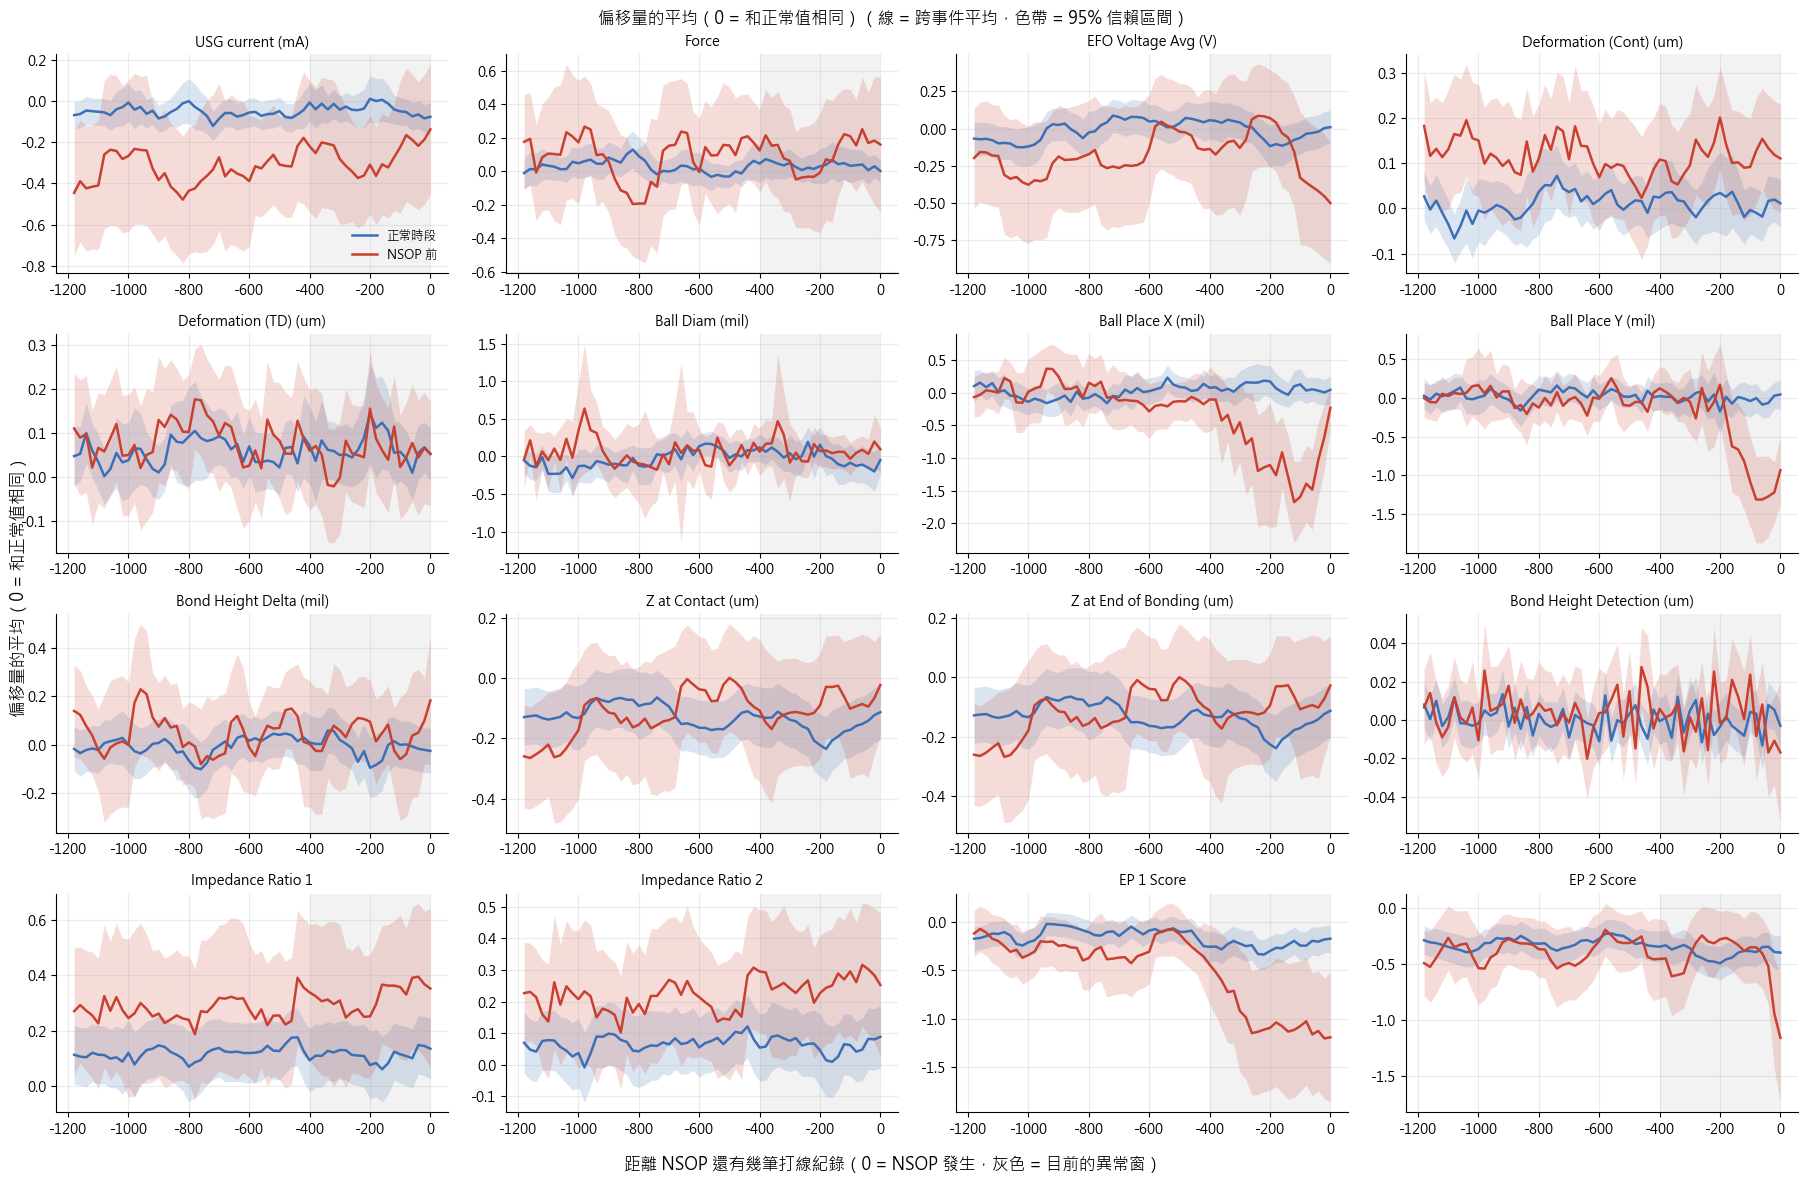

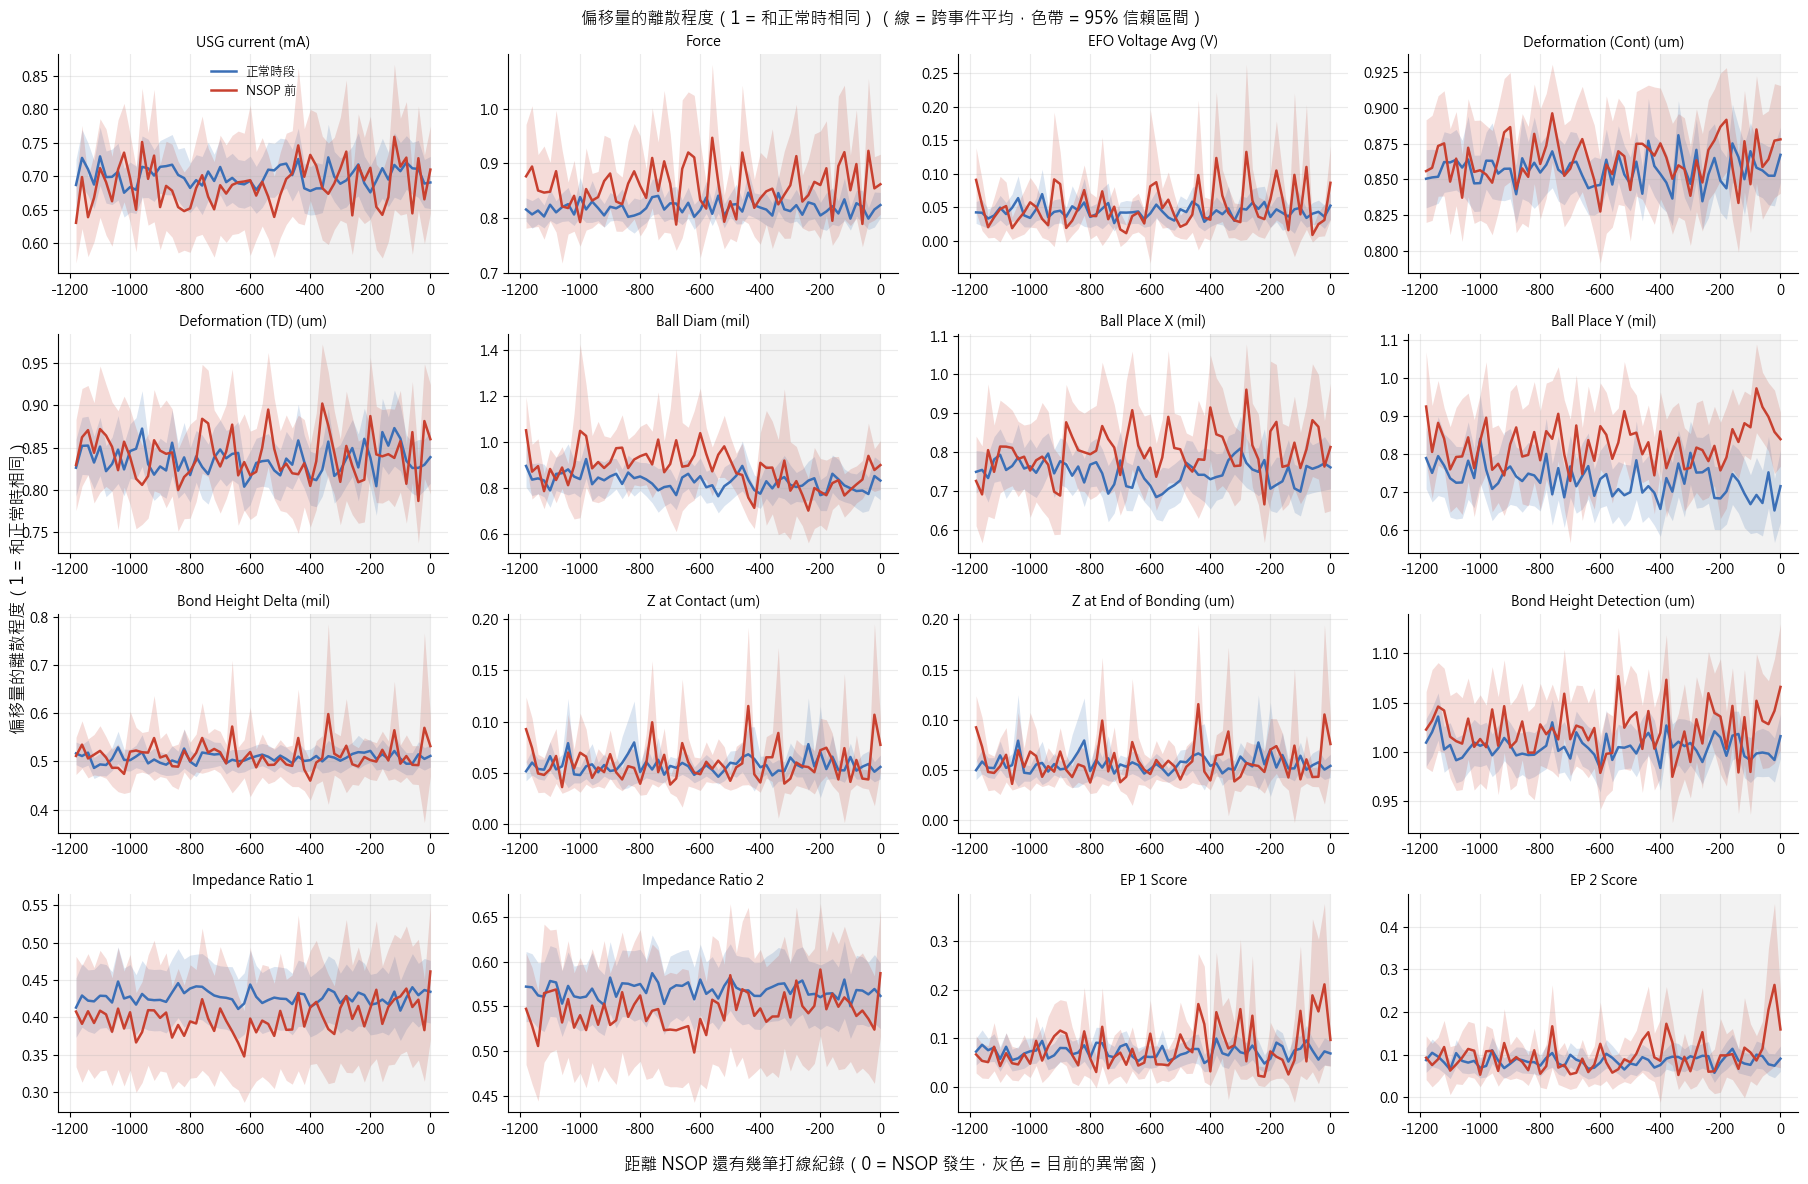

AUC：0.5 = 分不出來；越接近 1 = NSOP 前數值偏高；越接近 0 = NSOP 前數值偏低


,訊號,統計量,前 0~40 筆,前 40~100 筆,前 100~200 筆,前 200~400 筆,前 400~1200 筆,最大差異
0,Ball Place X (mil),平均,0.406,0.288,0.212,0.356,0.472,0.288
1,Ball Place Y (mil),平均,0.283,0.279,0.327,0.497,0.465,0.221
2,Ball Place Y (mil),離散,0.615,0.716,0.646,0.511,0.512,0.216
3,Impedance Ratio 1,平均,0.567,0.595,0.597,0.568,0.560,0.097
4,Ball Diam (mil),離散,0.533,0.594,0.456,0.420,0.518,0.094
5,Bond Height Detection (um),平均,0.479,0.497,0.591,0.510,0.543,0.091
6,Bond Height Detection (um),離散,0.539,0.591,0.518,0.553,0.588,0.091
7,USG current (mA),平均,0.464,0.449,0.419,0.410,0.421,0.090
8,Ball Place X (mil),離散,0.414,0.563,0.570,0.590,0.547,0.090
9,Deformation (Cont) (um),平均,0.549,0.575,0.574,0.570,0.587,0.087


In [34]:
# ================= 第 1 步（畫圖 + 數字）：NSOP 前的訊號和正常時段有沒有差別 =================
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Microsoft YaHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

WINDOW_ROWS = 400      # 目前暫定的異常窗長度（圖上的灰色區域）
MIN_BIN_COUNT = 10      # 一個點至少要有這麼多筆才列入
COLORS = {"NSOP 前": "#C8402F", "正常時段": "#3B6FB6"}


def curve(sig, stat, kind):
    """每個事件在每個區段的數值 → 跨事件的平均和 95% 信賴區間。"""
    s = df_bins.loc[(df_bins["kind"] == kind) & (df_bins[f"{sig}||count"] >= MIN_BIN_COUNT),
                    ["bin", f"{sig}||{stat}"]].dropna()
    g = s.groupby("bin")[f"{sig}||{stat}"]#根據每兩百筆作分組
    m, se = g.mean(), g.std() / np.sqrt(g.count())
    return m.index.values, m.values, (1.96 * se).values


def plot_grid(stat, title):
    ncol = 4
    nrow = int(np.ceil(len(sig_all) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 3.0 * nrow), squeeze=False)
    for ax, sig in zip(axes.ravel(), sig_all):
        for kind in ["正常時段", "NSOP 前"]:#根據正常事件、NSOP前各劃一條線
            x, m, ci = curve(sig, stat, kind)
            ax.plot(-x, m, color=COLORS[kind], lw=1.8, label=kind)
            ax.fill_between(-x, m - ci, m + ci, color=COLORS[kind], alpha=0.18, lw=0)
        ax.axvspan(-WINDOW_ROWS, 0, color="0.5", alpha=0.10, lw=0)
        ax.set_title(sig, fontsize=10)
        ax.grid(alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)
    for ax in axes.ravel()[len(sig_all):]:
        ax.set_visible(False)
    axes[0, 0].legend(frameon=False, fontsize=9)
    fig.supxlabel("距離 NSOP 還有幾筆打線紀錄（0 = NSOP 發生，灰色 = 目前的異常窗）")
    fig.supylabel(title)
    fig.suptitle(f"{title}（線 = 跨事件平均，色帶 = 95% 信賴區間）", fontsize=12)
    fig.tight_layout()
    plt.show()


plot_grid("mean", "偏移量的平均（0 = 和正常值相同）")
plot_grid("std", "偏移量的離散程度（1 = 和正常時相同）")


# ---------- 數字：每個訊號、距離 NSOP 不同遠近的區段，能不能分辨「NSOP 前」和「正常時段」----------
def auc(pos, neg):
    """AUC：隨機挑一個 NSOP 前的區段和一個正常區段，前者數值較大的機率。0.5 = 完全分不出來。"""
    pos, neg = np.asarray(pos, float), np.asarray(neg, float)
    pos, neg = pos[~np.isnan(pos)], neg[~np.isnan(neg)]
    if len(pos) < 5 or len(neg) < 5: #任何一群樣本數少於5不計算
        return np.nan
    r = pd.Series(np.concatenate([pos, neg])).rank().values
    return (r[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg))


segments = [(0, 40), (40, 100), (100, 200), (200, 400), (400, LOOK_ROWS)]
rows = []
for sig in sig_all:
    for stat, stat_name in [("mean", "平均"), ("std", "離散")]:
        row = {"訊號": sig, "統計量": stat_name}
        for lo, hi in segments:
            s = df_bins[(df_bins["bin"] >= lo) & (df_bins["bin"] < hi) & (df_bins[f"{sig}||count"] >= MIN_BIN_COUNT)]
            per = s.groupby(["kind", "eid"], observed=True)[f"{sig}||{stat}"].mean()
            a = (auc(per.loc["NSOP 前"], per.loc["正常時段"])
                 if {"NSOP 前", "正常時段"} <= set(per.index.get_level_values(0)) else np.nan)
            row[f"前 {lo}~{hi} 筆"] = a
        rows.append(row)

df_auc = pd.DataFrame(rows)
seg_cols = [c for c in df_auc.columns if c.startswith("前 ")]
df_auc["最大差異"] = (df_auc[seg_cols] - 0.5).abs().max(axis=1)#每格減0.5代表離分不出來有多遠，取絕對值是因為正負其實不影響，只是方向問題
df_auc = df_auc.sort_values("最大差異", ascending=False).reset_index(drop=True)
print("AUC：0.5 = 分不出來；越接近 1 = NSOP 前數值偏高；越接近 0 = NSOP 前數值偏低")
display(df_auc.round(3))

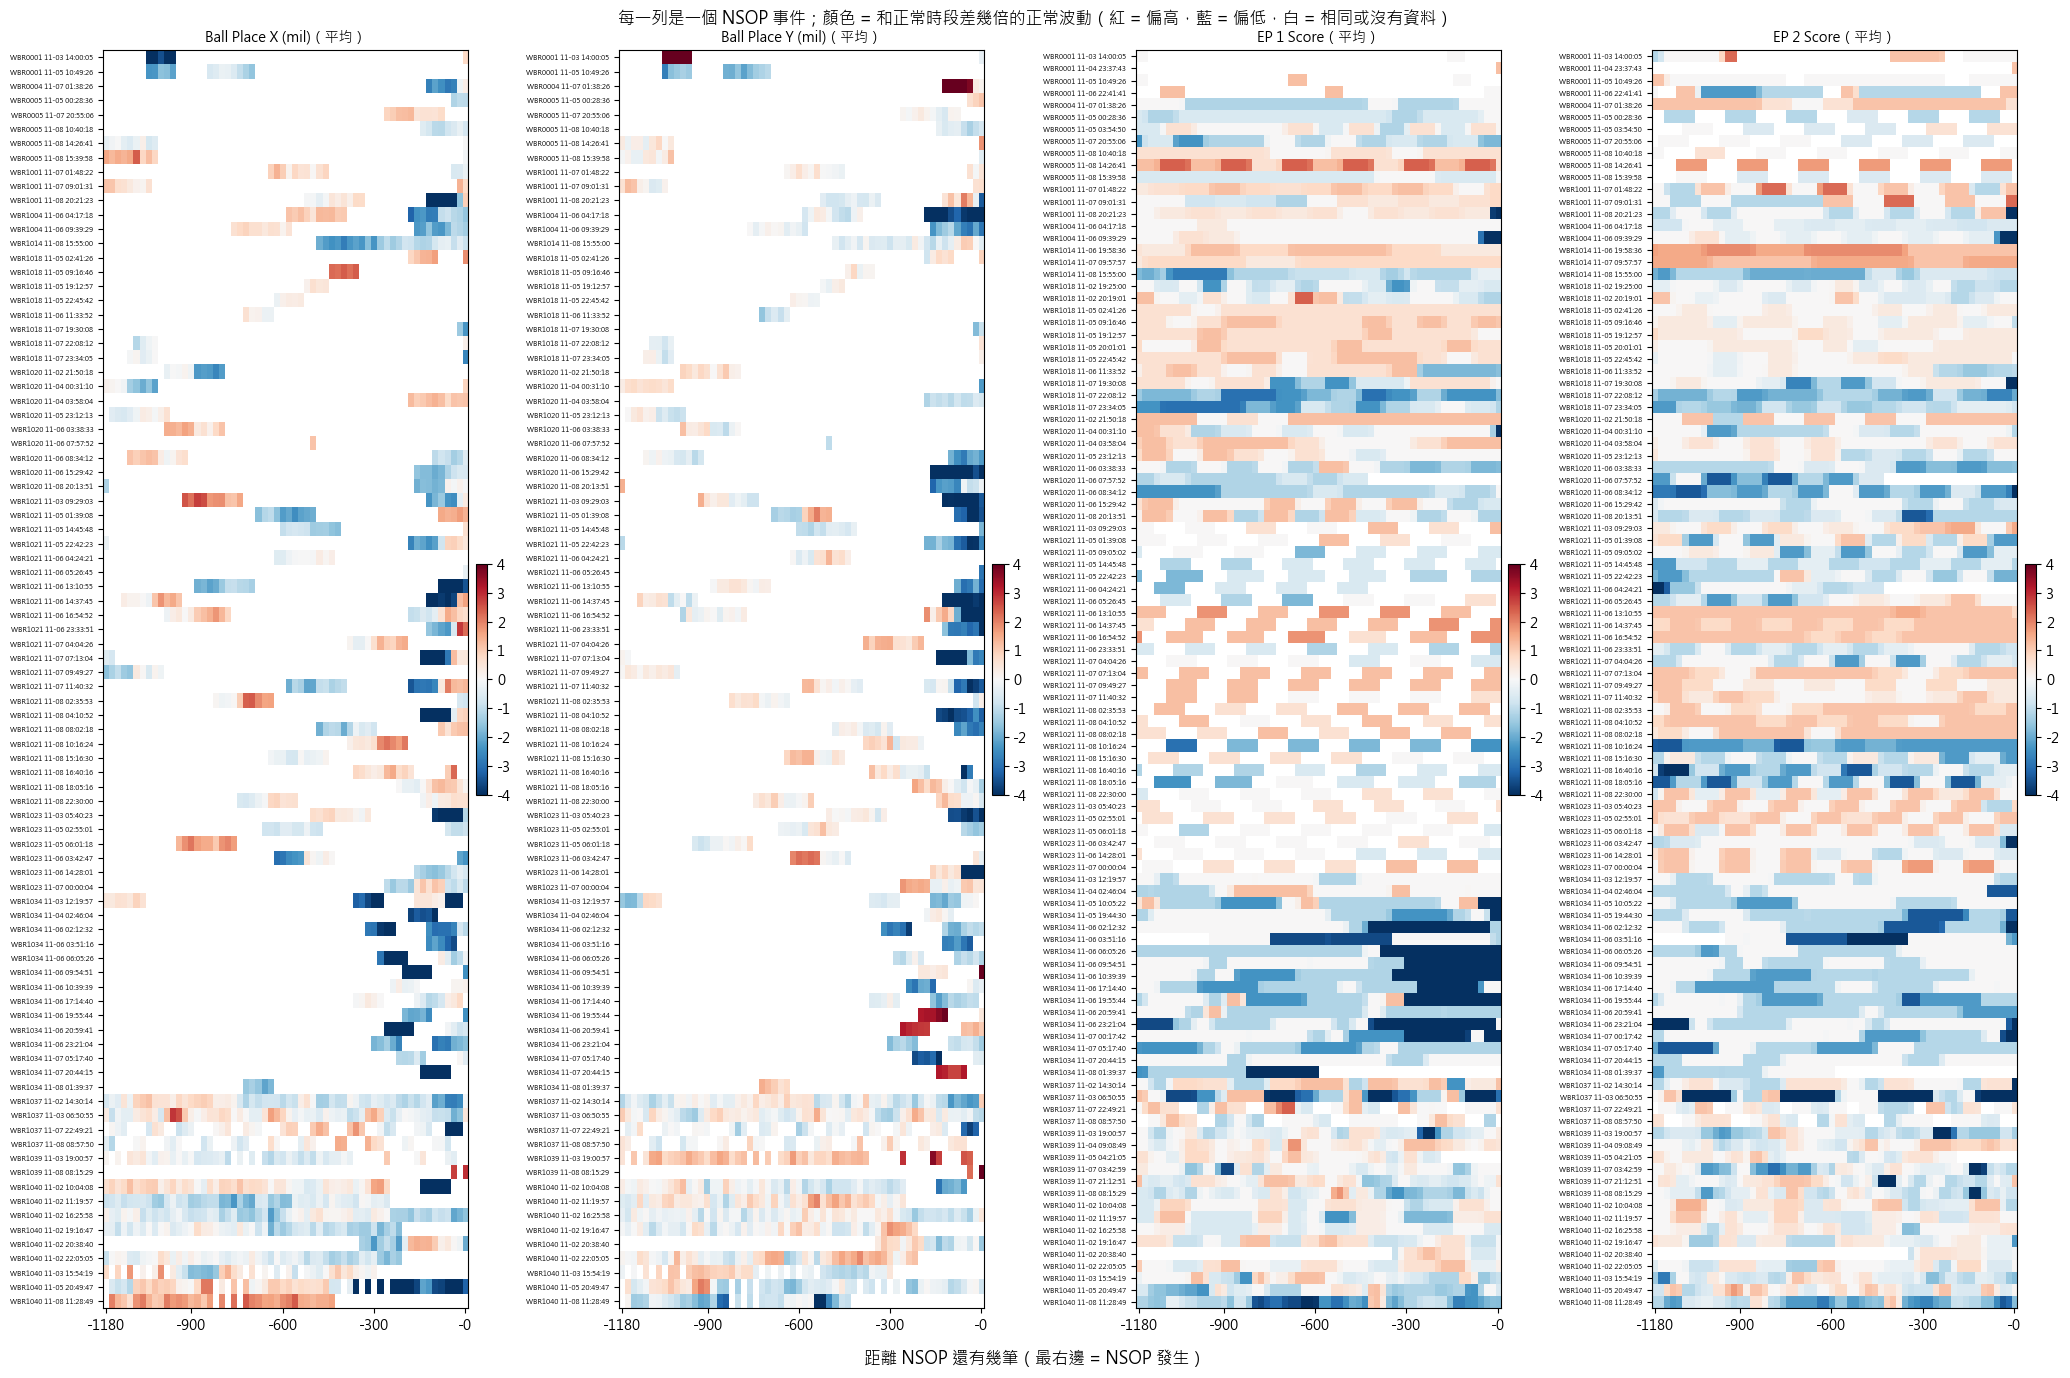

In [35]:
# ================= 每個事件各自的走勢：有多少個事件在 NSOP 前出現變化 =================
SHOW = [("Ball Place X (mil)", "mean"), ("Ball Place Y (mil)", "mean"),
        ("EP 1 Score", "mean"), ("EP 2 Score", "mean")]

fig, axes = plt.subplots(1, len(SHOW), figsize=(5.2 * len(SHOW), 14), squeeze=False)
for ax, (sig, stat) in zip(axes[0], SHOW):
    s = df_bins[(df_bins["kind"] == "NSOP 前") & (df_bins[f"{sig}||count"] >= MIN_BIN_COUNT)]
    mat = s.pivot(index="eid", columns="bin", values=f"{sig}||{stat}")
    mat = mat[sorted(mat.columns, reverse=True)]                      # 左邊離 NSOP 遠，右邊 = NSOP
    ref = df_bins.loc[df_bins["kind"] == "正常時段", f"{sig}||{stat}"]
    center, spread = ref.median(), ref.std()
    im = ax.imshow((mat.values - center) / spread, aspect="auto", cmap="RdBu_r", vmin=-4, vmax=4,
                   interpolation="nearest")
    ax.set_title(f"{sig}（{'平均' if stat == 'mean' else '離散'}）", fontsize=10)
    ticks = np.linspace(0, mat.shape[1] - 1, 5).astype(int)
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"-{mat.columns[i]}" for i in ticks])
    ax.set_yticks(range(len(mat)))
    ax.set_yticklabels(mat.index, fontsize=5)
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
fig.supxlabel("距離 NSOP 還有幾筆（最右邊 = NSOP 發生）")
fig.suptitle("每一列是一個 NSOP 事件；顏色 = 和正常時段差幾倍的正常波動（紅 = 偏高，藍 = 偏低，白 = 相同或沒有資料）")
fig.tight_layout()
plt.show()